Map shape: (3, 16, 16)
Path shape: (1, 16, 16)
Start: (np.int64(3), np.int64(7))
Goal: (np.int64(12), np.int64(7))
A* path length: 18


findfont: Failed to find font weight medium for DejaVu Serif, now using 400.


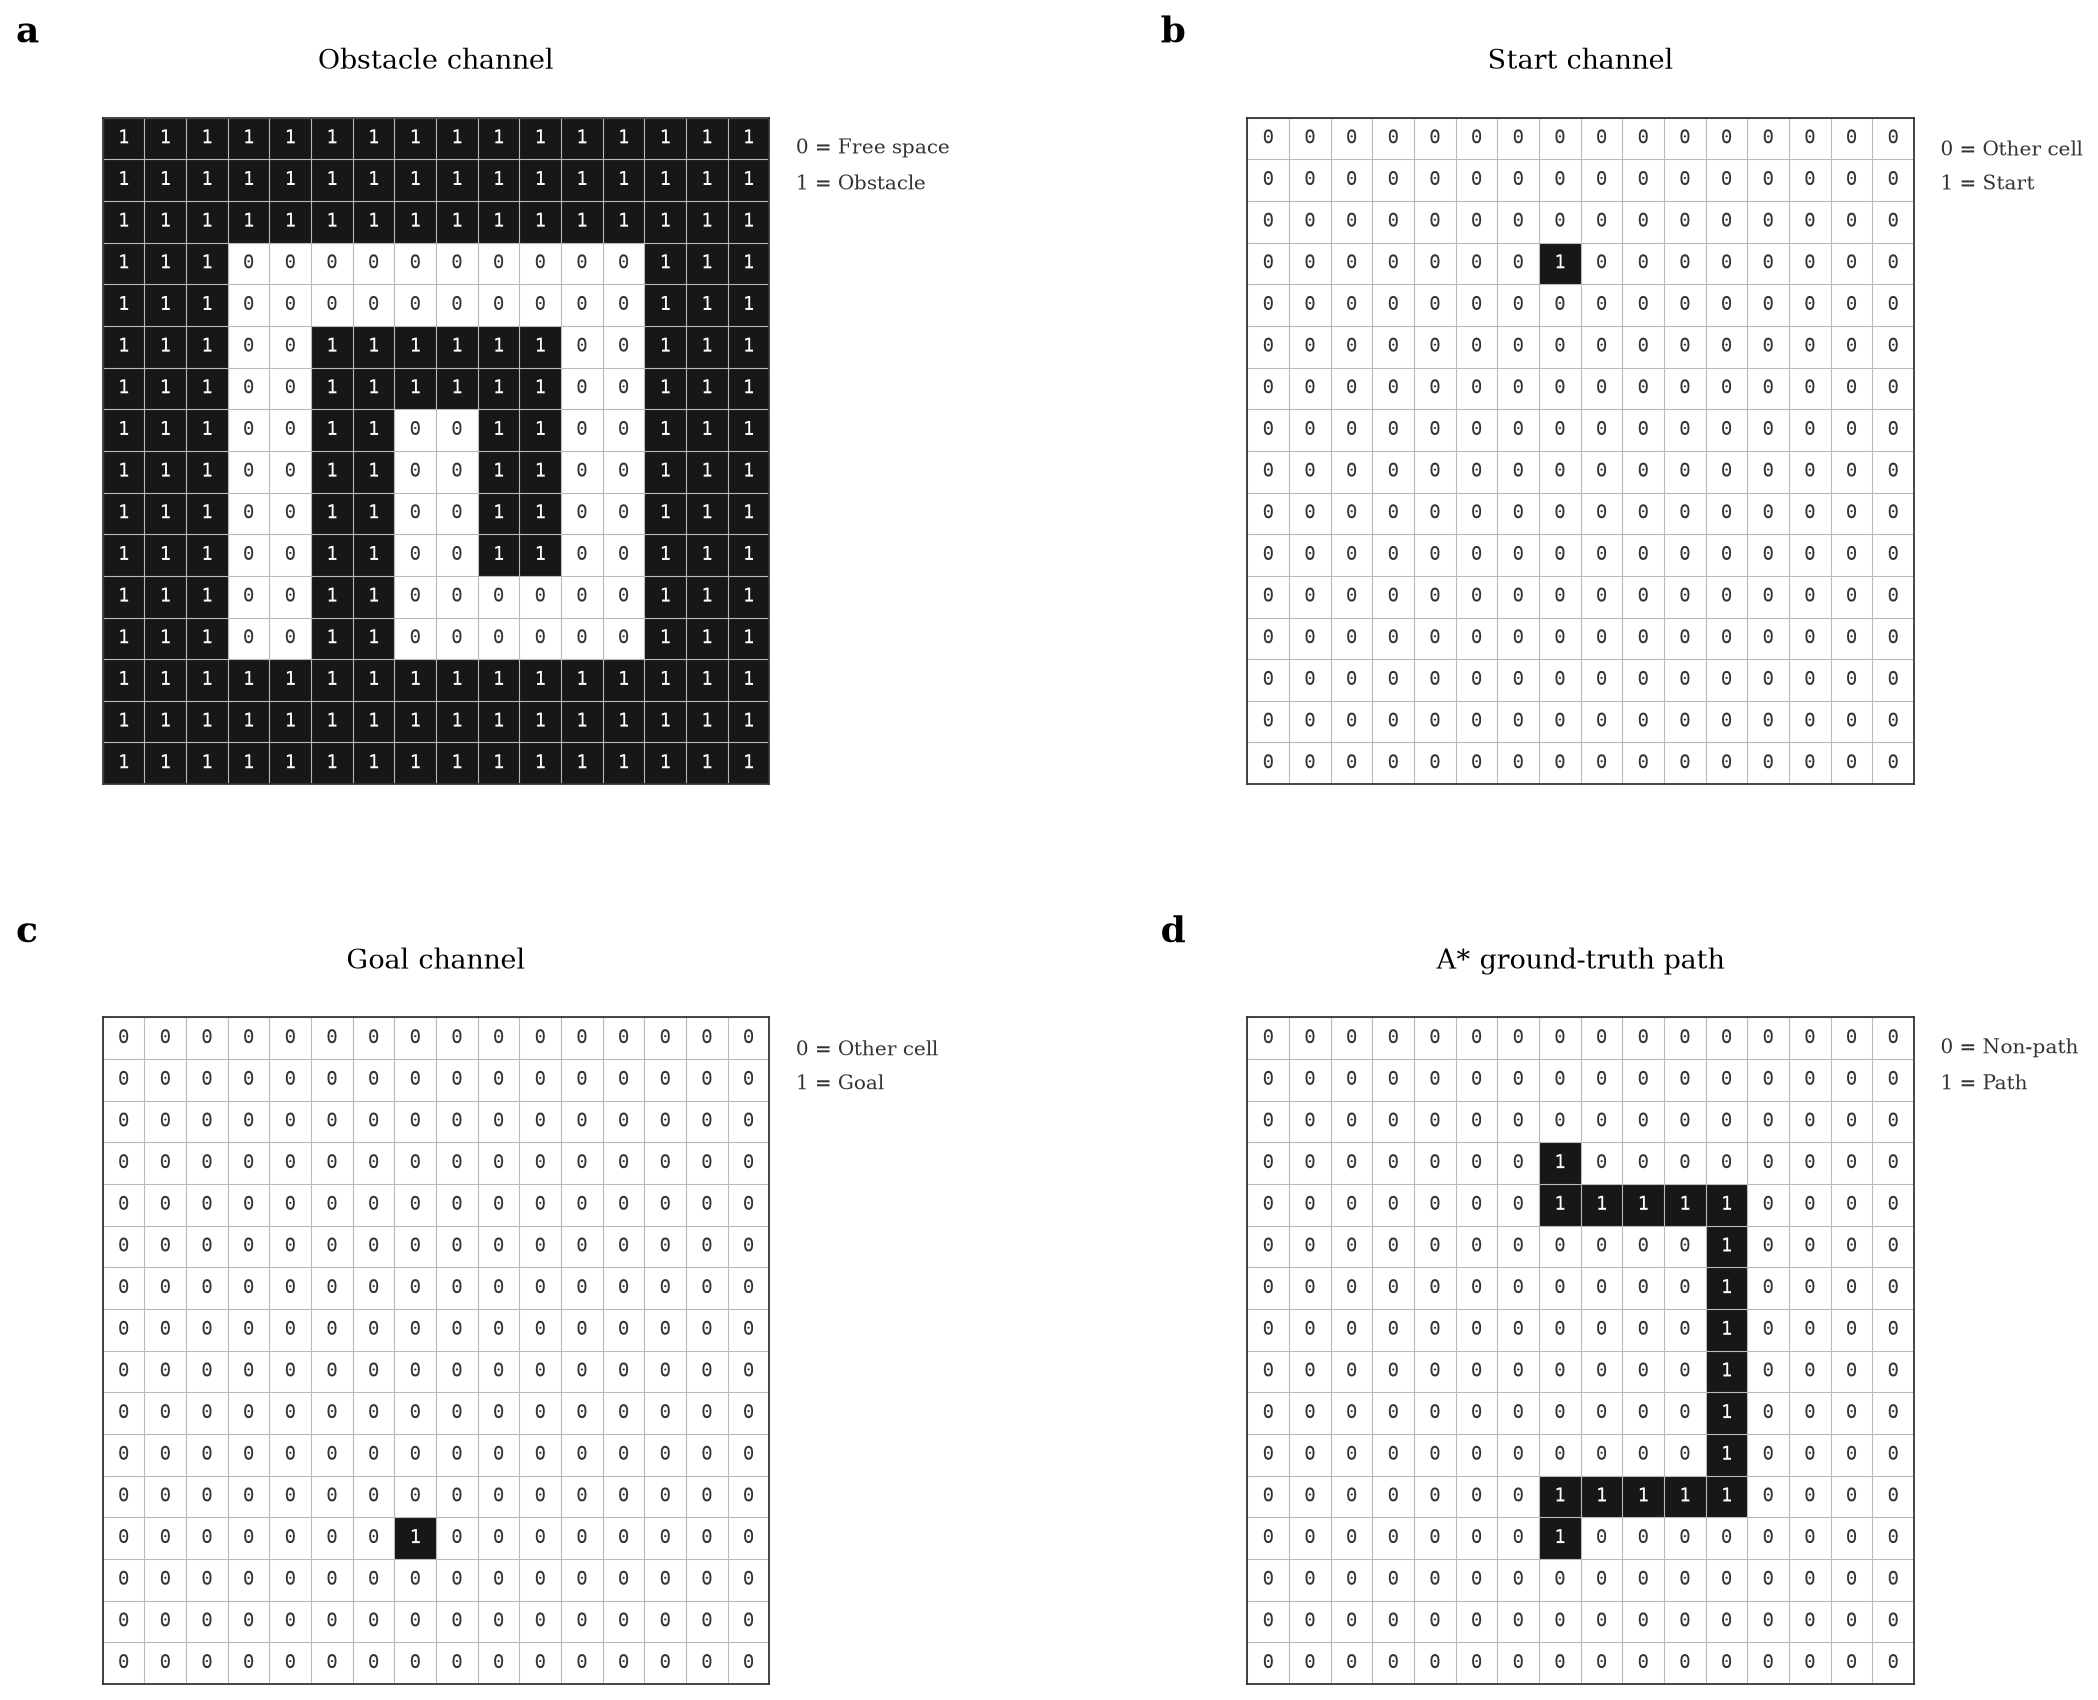

In [2]:
import heapq
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ============================================================
# 1. Configuration
# ============================================================

GRID_SIZE = 16
LOGICAL_MAZE_SIZE = 3
LOOP_PROB = 0.08
SEED = 42

# Adjusted for the smaller 16x16 maze
MIN_START_GOAL_DISTANCE = 6
MIN_PATH_LENGTH = 12
MIN_DETOUR_RATIO = 1.2

MAX_START_GOAL_TRIES = 300
MAX_MAZE_TRIES = 1000

# Independent RNG for reproducibility
rng = np.random.RandomState(SEED)


# ============================================================
# 2. Manhattan distance
# ============================================================

def heuristic(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


# ============================================================
# 3. A* shortest path (4-connected)
# ============================================================

def astar(obstacle_map, start, goal):

    H, W = obstacle_map.shape

    open_heap = [(heuristic(start, goal), 0, start)]
    came_from = {}
    g_score = {start: 0}
    visited = set()

    directions = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1)
    ]

    while open_heap:

        f, g, current = heapq.heappop(open_heap)

        if current in visited:
            continue

        visited.add(current)

        if current == goal:
            path = [current]

            while current in came_from:
                current = came_from[current]
                path.append(current)

            return path[::-1]

        r, c = current

        for dr, dc in directions:

            nr, nc = r + dr, c + dc

            if not (0 <= nr < H and 0 <= nc < W):
                continue

            if obstacle_map[nr, nc] == 1:
                continue

            neighbor = (nr, nc)
            tentative_g = g_score[current] + 1

            if (
                neighbor not in g_score
                or tentative_g < g_score[neighbor]
            ):

                came_from[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = (
                    tentative_g + heuristic(neighbor, goal)
                )

                heapq.heappush(
                    open_heap,
                    (f_score, tentative_g, neighbor)
                )

    return None


# ============================================================
# 4. Generate maze using Randomized DFS
# ============================================================

def generate_maze():

    logical_size = LOGICAL_MAZE_SIZE
    maze_size = 2 * logical_size + 1

    maze = np.ones(
        (maze_size, maze_size),
        dtype=np.int32
    )

    visited = np.zeros(
        (logical_size, logical_size),
        dtype=bool
    )

    directions = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1)
    ]

    # Random initial logical cell
    start_r = rng.randint(logical_size)
    start_c = rng.randint(logical_size)

    stack = [(start_r, start_c)]
    visited[start_r, start_c] = True
    maze[2 * start_r + 1, 2 * start_c + 1] = 0

    # Randomized DFS
    while stack:

        r, c = stack[-1]
        neighbors = []

        for dr, dc in directions:

            nr, nc = r + dr, c + dc

            if (
                0 <= nr < logical_size
                and 0 <= nc < logical_size
                and not visited[nr, nc]
            ):
                neighbors.append((nr, nc, dr, dc))

        if not neighbors:
            stack.pop()
            continue

        idx = rng.randint(len(neighbors))
        nr, nc, dr, dc = neighbors[idx]

        # Remove wall between two logical cells
        maze[2 * r + 1 + dr, 2 * c + 1 + dc] = 0
        maze[2 * nr + 1, 2 * nc + 1] = 0

        visited[nr, nc] = True
        stack.append((nr, nc))

    # --------------------------------------------------------
    # Add loops through random wall removal
    # --------------------------------------------------------

    candidate_walls = []

    for r in range(1, maze_size - 1):
        for c in range(1, maze_size - 1):

            if maze[r, c] != 1:
                continue

            if r % 2 == 1 and c % 2 == 0:

                if maze[r, c-1] == 0 and maze[r, c+1] == 0:
                    candidate_walls.append((r, c))

            elif r % 2 == 0 and c % 2 == 1:

                if maze[r-1, c] == 0 and maze[r+1, c] == 0:
                    candidate_walls.append((r, c))

    for r, c in candidate_walls:
        if rng.rand() < LOOP_PROB:
            maze[r, c] = 0

    # --------------------------------------------------------
    # Upscale x2 and add one-cell wall border
    # --------------------------------------------------------

    maze = np.repeat(
        np.repeat(maze, 2, axis=0),
        2,
        axis=1
    )

    maze = np.pad(
        maze,
        pad_width=1,
        mode="constant",
        constant_values=1
    )

    assert maze.shape == (GRID_SIZE, GRID_SIZE)

    return maze


# ============================================================
# 5. Generate ONE map-path pair
# ============================================================

def generate_sample():

    for maze_attempt in range(MAX_MAZE_TRIES):

        obstacle_map = generate_maze()

        free_cells = np.argwhere(obstacle_map == 0)

        for _ in range(MAX_START_GOAL_TRIES):

            indices = rng.choice(
                len(free_cells),
                size=2,
                replace=False
            )

            start = tuple(free_cells[indices[0]])
            goal = tuple(free_cells[indices[1]])

            distance = heuristic(start, goal)

            if distance < MIN_START_GOAL_DISTANCE:
                continue

            path = astar(obstacle_map, start, goal)

            if path is None:
                continue

            if len(path) < MIN_PATH_LENGTH:
                continue

            detour_ratio = (len(path) - 1) / max(distance, 1)

            if detour_ratio < MIN_DETOUR_RATIO:
                continue

            # Build 3-channel map
            map_tensor = np.zeros(
                (3, GRID_SIZE, GRID_SIZE),
                dtype=np.int32
            )

            map_tensor[0] = obstacle_map
            map_tensor[1, start[0], start[1]] = 1
            map_tensor[2, goal[0], goal[1]] = 1

            # Build single-channel A* path
            path_tensor = np.zeros(
                (1, GRID_SIZE, GRID_SIZE),
                dtype=np.int32
            )

            for r, c in path:
                path_tensor[0, r, c] = 1

            return (
                map_tensor,
                path_tensor,
                start,
                goal,
                len(path)
            )

    raise RuntimeError(
        "Could not generate a maze satisfying the constraints."
    )


# ============================================================
# 6. Generate just ONE sample (no dataset saving)
# ============================================================

map_tensor, path_tensor, start, goal, path_length = (
    generate_sample()
)

assert map_tensor.shape == (3, 16, 16)
assert path_tensor.shape == (1, 16, 16)

print("Map shape:", map_tensor.shape)
print("Path shape:", path_tensor.shape)
print("Start:", start)
print("Goal:", goal)
print("A* path length:", path_length)


# ============================================================
# 7. Nature-inspired binary channel figure
# ============================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.linewidth": 0.8,
    "figure.facecolor": "white",
    "savefig.facecolor": "white"
})

channels = [
    map_tensor[0],
    map_tensor[1],
    map_tensor[2],
    path_tensor[0]
]

titles = [
    "Obstacle channel",
    "Start channel",
    "Goal channel",
    "A* ground-truth path"
]

descriptions = [
    ("0 = Free space", "1 = Obstacle"),
    ("0 = Other cell", "1 = Start"),
    ("0 = Other cell", "1 = Goal"),
    ("0 = Non-path", "1 = Path")
]

panel_labels = ["a", "b", "c", "d"]

# Black = 1, White = 0
binary_cmap = ListedColormap(["#FFFFFF", "#171717"])

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 11),
    dpi=160
)

fig.subplots_adjust(
    left=0.05,
    right=0.94,
    top=0.95,
    bottom=0.06,
    wspace=0.62,
    hspace=0.35
)

for ax, channel, title, desc, label in zip(
    axes.flat,
    channels,
    titles,
    descriptions,
    panel_labels
):

    # Draw exact binary cells
    ax.imshow(
        channel,
        cmap=binary_cmap,
        vmin=0,
        vmax=1,
        interpolation="nearest",
        origin="upper"
    )

    # 16x16 cell boundaries
    ax.set_xticks(
        np.arange(-0.5, GRID_SIZE, 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, GRID_SIZE, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="#B9B9B9",
        linewidth=0.5
    )

    # Explicit 0/1 labels inside each cell
    for r in range(GRID_SIZE):
        for c in range(GRID_SIZE):

            value = int(channel[r, c])

            ax.text(
                c, r,
                str(value),
                ha="center",
                va="center",
                fontsize=8.5,
                family="DejaVu Sans Mono",
                color="white" if value == 1 else "#333333"
            )

    ax.set_xticks([])
    ax.set_yticks([])
    ax.tick_params(
        which="both",
        bottom=False,
        left=False
    )

    # Thin outer border
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#333333")

    # Panel label
    ax.text(
        -0.13, 1.10,
        label,
        transform=ax.transAxes,
        fontsize=16,
        fontweight="bold",
        ha="left",
        va="bottom",
        clip_on=False
    )

    # Channel title
    ax.set_title(
        title,
        fontsize=12,
        fontweight="medium",
        pad=22
    )

    # Binary legend OUTSIDE upper-right of each panel
    ax.text(
        1.04, 0.98,
        desc[0] + "\n" + desc[1],
        transform=ax.transAxes,
        fontsize=9,
        color="#333333",
        ha="left",
        va="top",
        linespacing=1.7,
        clip_on=False
    )

plt.show()

Raw map: (3, 16, 16)
Directional channels: (4, 16, 16)
Final representation: (7, 16, 16)
Selected cell: (8, 3)
Up, Down, Left, Right: [1, 1, 0, 1]


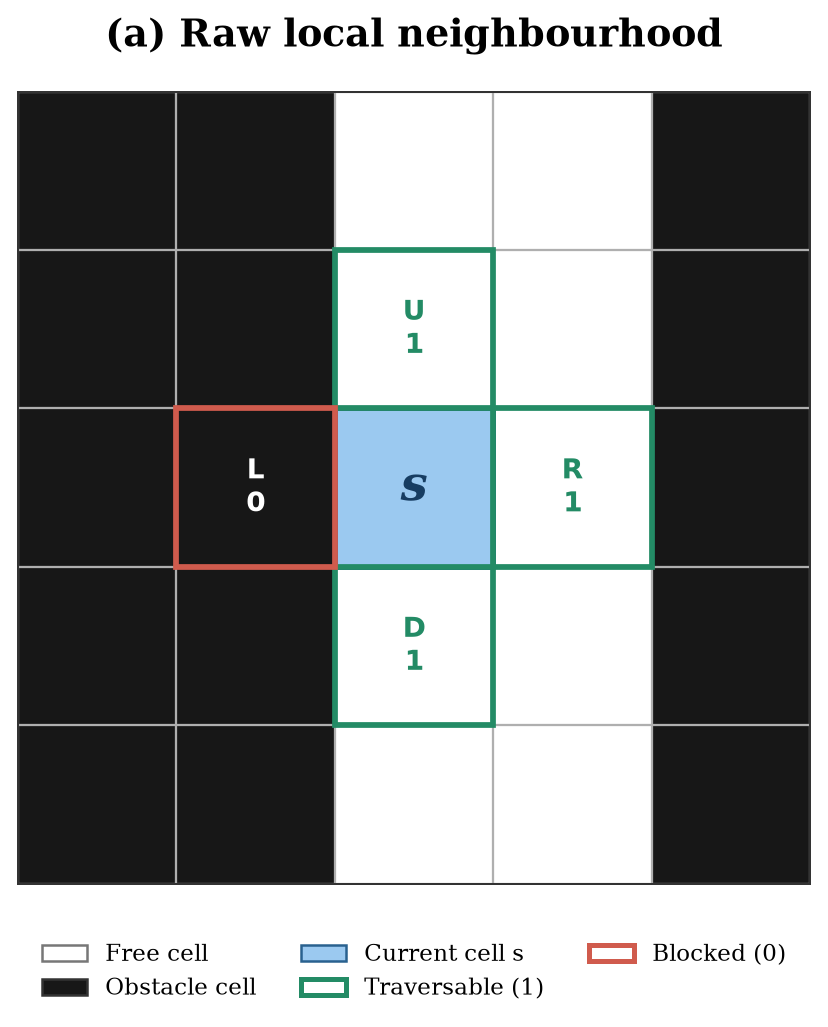

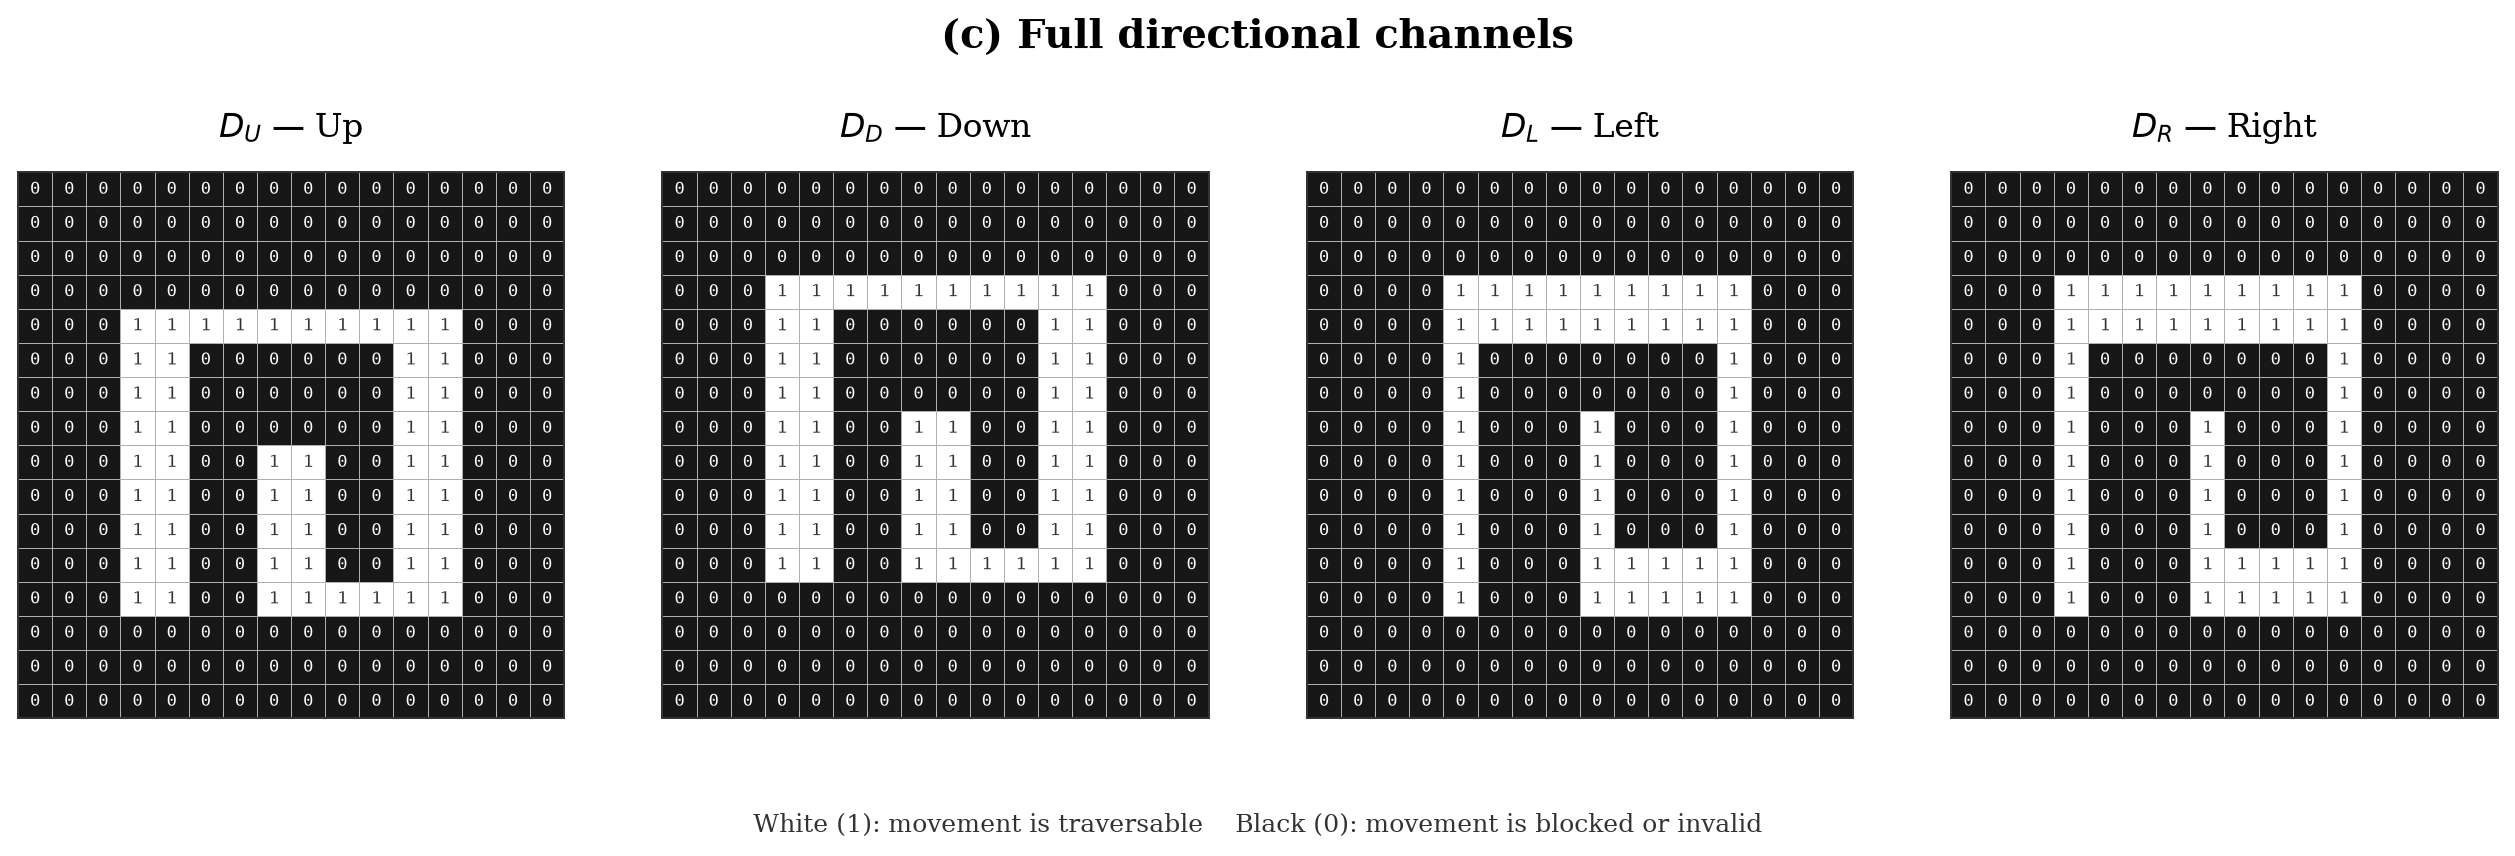

In [3]:
# ============================================================
# 8. Directional Representation Figure
#    Panel (a): Raw local neighbourhood
#    Panel (c): Four directional channels
#
# Reuse map_tensor from the previous code.
# No new maze or map-path pair is generated.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle, Patch

# ------------------------------------------------------------
# 8.1 Construct directional channels
# ------------------------------------------------------------

obstacle_map = map_tensor[0].astype(np.int32)

H, W = obstacle_map.shape

free = (obstacle_map == 0)

# Direction order: Up, Down, Left, Right
directional = np.zeros((4, H, W), dtype=np.int32)

# Up: current cell and cell above must be free
directional[0, 1:, :] = (
    free[1:, :] & free[:-1, :]
).astype(np.int32)

# Down
directional[1, :-1, :] = (
    free[:-1, :] & free[1:, :]
).astype(np.int32)

# Left
directional[2, :, 1:] = (
    free[:, 1:] & free[:, :-1]
).astype(np.int32)

# Right
directional[3, :, :-1] = (
    free[:, :-1] & free[:, 1:]
).astype(np.int32)

D_U, D_D, D_L, D_R = directional

# Final 7-channel representation
directional_representation = np.concatenate(
    [map_tensor, directional],
    axis=0
)

assert directional_representation.shape == (7, H, W)

print("Raw map:", map_tensor.shape)
print("Directional channels:", directional.shape)
print("Final representation:", directional_representation.shape)


# ------------------------------------------------------------
# 8.2 Select a representative cell for Panel (a)
# ------------------------------------------------------------
# Prefer a cell with:
# - exactly 3 traversable directions
# - at least one blocked direction
# - sufficient distance from the outer border
#
# This creates a more informative illustration than
# selecting an arbitrary free cell.
# ------------------------------------------------------------

num_directions = directional.sum(axis=0)

candidates = []

for r in range(2, H - 2):
    for c in range(2, W - 2):

        if obstacle_map[r, c] != 0:
            continue

        if num_directions[r, c] == 3:
            candidates.append((r, c))

# If no 3-direction junction exists, use a 2-direction cell.
if not candidates:

    for r in range(2, H - 2):
        for c in range(2, W - 2):

            if (
                obstacle_map[r, c] == 0
                and num_directions[r, c] == 2
            ):
                candidates.append((r, c))

if not candidates:
    raise RuntimeError(
        "No suitable free cell found for the illustration."
    )

# Deterministic selection, independent of the sample RNG
center_r, center_c = candidates[len(candidates) // 2]

local_map = obstacle_map[
    center_r - 2:center_r + 3,
    center_c - 2:center_c + 3
]

local_direction = directional[:, center_r, center_c]

print("Selected cell:", (center_r, center_c))
print(
    "Up, Down, Left, Right:",
    local_direction.tolist()
)


# ------------------------------------------------------------
# 8.3 Plot style
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.linewidth": 0.8,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

binary_cmap = ListedColormap([
    "#FFFFFF",  # 0 = white
    "#171717"   # 1 = black
])

# For directional channels:
# 0 = blocked -> dark
# 1 = traversable -> white
direction_cmap = ListedColormap([
    "#171717",
    "#FFFFFF"
])

FREE_COLOR = "#FFFFFF"
OBSTACLE_COLOR = "#171717"
CENTER_COLOR = "#9BC9F0"
VALID_COLOR = "#238B65"
BLOCKED_COLOR = "#D05B4D"


# ------------------------------------------------------------
# 8.4 Helper: binary grid with explicit 0/1 labels
# ------------------------------------------------------------

def draw_binary_grid(
    ax,
    channel,
    cmap,
    show_values=True,
    fontsize=8,
    grid_width=0.45
):

    h, w = channel.shape

    ax.imshow(
        channel,
        cmap=cmap,
        vmin=0,
        vmax=1,
        interpolation="nearest",
        origin="upper"
    )

    ax.set_xticks(
        np.arange(-0.5, w, 1),
        minor=True
    )
    ax.set_yticks(
        np.arange(-0.5, h, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="#AFAFAF",
        linewidth=grid_width
    )

    if show_values:
        for r in range(h):
            for c in range(w):

                value = int(channel[r, c])

                # Directional channel:
                # 1 is white and 0 is black
                is_white = (
                    (cmap is direction_cmap and value == 1)
                    or
                    (cmap is binary_cmap and value == 0)
                )

                ax.text(
                    c,
                    r,
                    str(value),
                    ha="center",
                    va="center",
                    fontsize=fontsize,
                    fontfamily="DejaVu Sans Mono",
                    color="#333333" if is_white else "white"
                )

    ax.set_xticks([])
    ax.set_yticks([])

    ax.tick_params(
        which="both",
        bottom=False,
        left=False
    )

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#333333")

    ax.set_aspect("equal")


# ============================================================
# 8.5 Panel (a): Raw local neighbourhood
# ============================================================

fig_a, ax_a = plt.subplots(
    figsize=(6.5, 6.2),
    dpi=180
)

draw_binary_grid(
    ax_a,
    local_map,
    binary_cmap,
    show_values=False,
    grid_width=0.9
)

# Highlight the central free cell
ax_a.add_patch(
    Rectangle(
        (1.5, 1.5),
        1,
        1,
        facecolor=CENTER_COLOR,
        edgecolor="#29618F",
        linewidth=2,
        zorder=3
    )
)

ax_a.text(
    2, 2, "s",
    ha="center",
    va="center",
    fontsize=19,
    fontstyle="italic",
    fontweight="bold",
    color="#173D62",
    zorder=5
)

# Mark four immediate neighbours
neighbours = [
    (1, 2, "U", local_direction[0]),
    (3, 2, "D", local_direction[1]),
    (2, 1, "L", local_direction[2]),
    (2, 3, "R", local_direction[3])
]

for nr, nc, label, valid in neighbours:

    color = VALID_COLOR if valid else BLOCKED_COLOR

    ax_a.add_patch(
        Rectangle(
            (nc - 0.5, nr - 0.5),
            1,
            1,
            facecolor="none",
            edgecolor=color,
            linewidth=2.3,
            zorder=4
        )
    )

    ax_a.text(
        nc, nr,
        f"{label}\n{int(valid)}",
        ha="center",
        va="center",
        fontsize=11,
        fontfamily="DejaVu Sans",
        fontweight="bold",
        color=color if valid else "white",
        zorder=5
    )

ax_a.set_title(
    "(a) Raw local neighbourhood",
    fontsize=15,
    fontweight="bold",
    pad=18
)

legend_handles = [
    Patch(
        facecolor=FREE_COLOR,
        edgecolor="#777777",
        label="Free cell"
    ),
    Patch(
        facecolor=OBSTACLE_COLOR,
        edgecolor="#333333",
        label="Obstacle cell"
    ),
    Patch(
        facecolor=CENTER_COLOR,
        edgecolor="#29618F",
        label="Current cell s"
    ),
    Patch(
        facecolor="none",
        edgecolor=VALID_COLOR,
        linewidth=2,
        label="Traversable (1)"
    ),
    Patch(
        facecolor="none",
        edgecolor=BLOCKED_COLOR,
        linewidth=2,
        label="Blocked (0)"
    )
]

ax_a.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=3,
    frameon=False,
    fontsize=9
)

fig_a.subplots_adjust(
    top=0.91,
    bottom=0.20,
    left=0.08,
    right=0.92
)

fig_a.savefig(
    "directional_panel_a.png",
    dpi=300,
    bbox_inches="tight"
)

fig_a.savefig(
    "directional_panel_a.pdf",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 8.6 Panel (c): Four full directional channels
# ============================================================

fig_c, axes = plt.subplots(
    1, 4,
    figsize=(14.5, 4.8),
    dpi=180
)

channel_titles = [
    r"$D_U$ — Up",
    r"$D_D$ — Down",
    r"$D_L$ — Left",
    r"$D_R$ — Right"
]

for ax, channel, title in zip(
    axes,
    directional,
    channel_titles
):

    draw_binary_grid(
        ax,
        channel,
        direction_cmap,
        show_values=True,
        fontsize=6.8,
        grid_width=0.4
    )

    ax.set_title(
        title,
        fontsize=13,
        pad=14
    )

fig_c.suptitle(
    "(c) Full directional channels",
    fontsize=16,
    fontweight="bold",
    y=0.98
)

fig_c.text(
    0.5,
    0.045,
    "White (1): movement is traversable    "
    "Black (0): movement is blocked or invalid",
    ha="center",
    va="center",
    fontsize=10,
    color="#333333"
)

fig_c.subplots_adjust(
    left=0.025,
    right=0.975,
    top=0.82,
    bottom=0.15,
    wspace=0.18
)

fig_c.savefig(
    "directional_panel_c.png",
    dpi=300,
    bbox_inches="tight"
)

fig_c.savefig(
    "directional_panel_c.pdf",
    bbox_inches="tight"
)

plt.show()

Raw map: (3, 16, 16)
Directional channels: (4, 16, 16)
Final representation: (7, 16, 16)
Selected cell: (8, 3)
Up, Down, Left, Right: [1, 1, 0, 1]


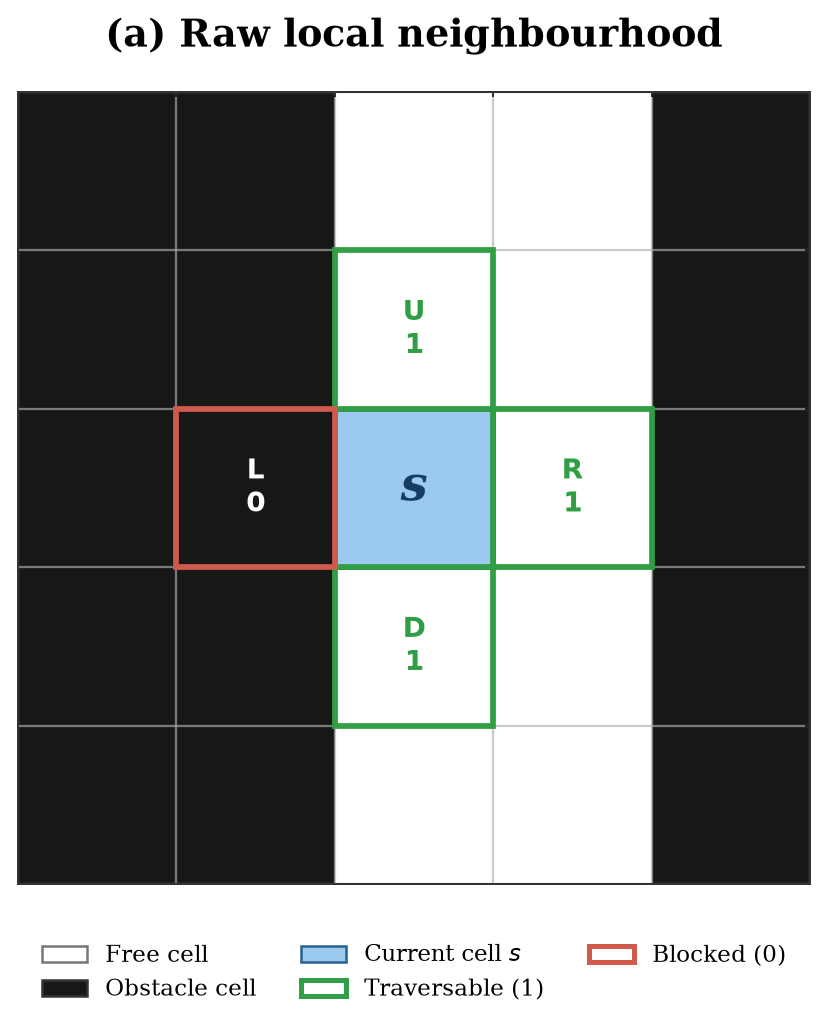

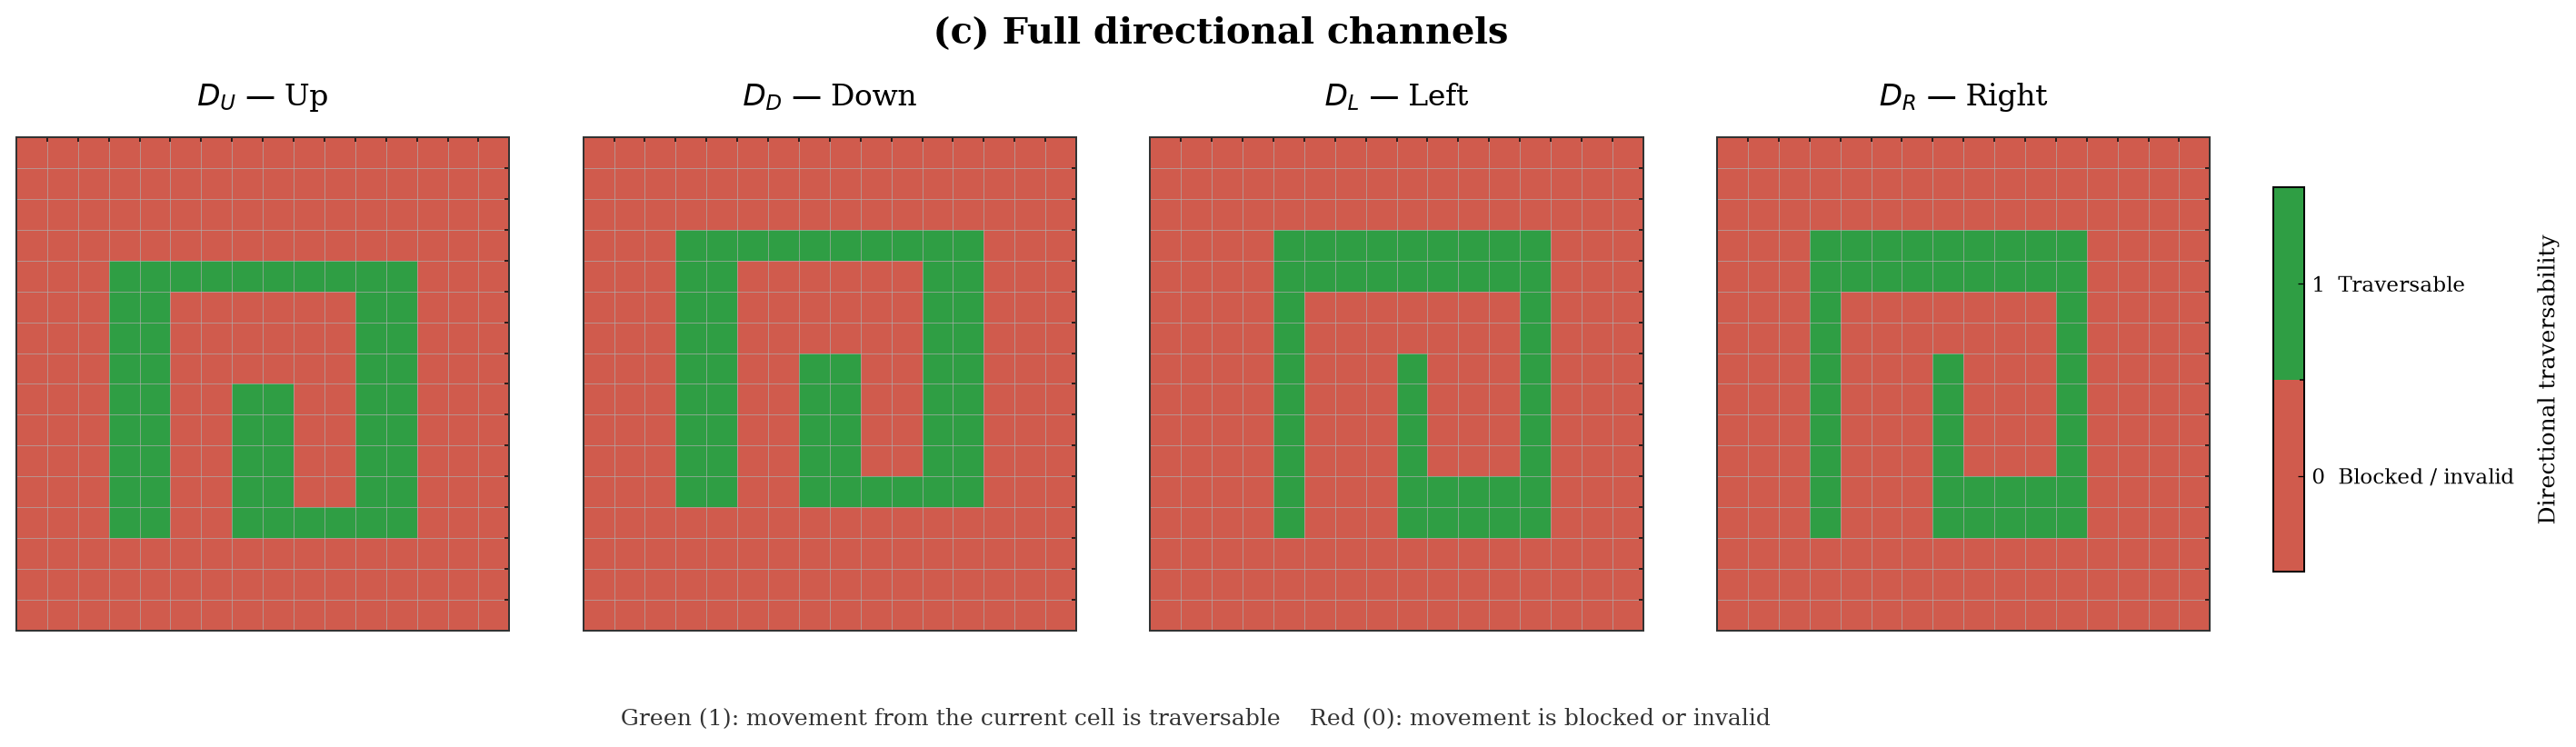

In [14]:
# ============================================================
# 8. Directional Representation Figure
#    Panel (a): Raw local neighbourhood
#    Panel (c): Four directional channels
#
# Reuse map_tensor from the previous code.
# No new maze or map-path pair is generated.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle, Patch
from matplotlib.ticker import FormatStrFormatter

# ------------------------------------------------------------
# 8.1 Construct directional channels
# ------------------------------------------------------------

obstacle_map = map_tensor[0].astype(np.int32)

H, W = obstacle_map.shape

free = (obstacle_map == 0)

# Direction order: Up, Down, Left, Right
directional = np.zeros((4, H, W), dtype=np.int32)

# Up: current cell and cell above must be free
directional[0, 1:, :] = (
    free[1:, :] & free[:-1, :]
).astype(np.int32)

# Down
directional[1, :-1, :] = (
    free[:-1, :] & free[1:, :]
).astype(np.int32)

# Left
directional[2, :, 1:] = (
    free[:, 1:] & free[:, :-1]
).astype(np.int32)

# Right
directional[3, :, :-1] = (
    free[:, :-1] & free[:, 1:]
).astype(np.int32)

D_U, D_D, D_L, D_R = directional

# Final 7-channel representation
directional_representation = np.concatenate(
    [map_tensor, directional],
    axis=0
)

assert directional_representation.shape == (7, H, W)

print("Raw map:", map_tensor.shape)
print("Directional channels:", directional.shape)
print("Final representation:", directional_representation.shape)


# ------------------------------------------------------------
# 8.2 Select a representative cell for Panel (a)
# ------------------------------------------------------------
# Prefer a cell with:
# - exactly 3 traversable directions
# - at least one blocked direction
# - sufficient distance from the outer border
# ------------------------------------------------------------

num_directions = directional.sum(axis=0)

candidates = []

for r in range(2, H - 2):
    for c in range(2, W - 2):

        if obstacle_map[r, c] != 0:
            continue

        if num_directions[r, c] == 3:
            candidates.append((r, c))

# If no 3-direction junction exists, use a 2-direction cell.
if not candidates:

    for r in range(2, H - 2):
        for c in range(2, W - 2):

            if (
                obstacle_map[r, c] == 0
                and num_directions[r, c] == 2
            ):
                candidates.append((r, c))

if not candidates:
    raise RuntimeError(
        "No suitable free cell found for the illustration."
    )

# Deterministic selection
center_r, center_c = candidates[len(candidates) // 2]

local_map = obstacle_map[
    center_r - 2:center_r + 3,
    center_c - 2:center_c + 3
]

local_direction = directional[:, center_r, center_c]

print("Selected cell:", (center_r, center_c))
print(
    "Up, Down, Left, Right:",
    local_direction.tolist()
)


# ------------------------------------------------------------
# 8.3 Plot style
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 6,
    "axes.linewidth": 0.8,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "xtick.direction": "in",
    "ytick.direction": "in",
})

# Raw neighbourhood map style
binary_cmap = ListedColormap([
    "#FFFFFF",  # free
    "#171717"   # obstacle
])

# Directional channels:
# 0 = blocked / invalid -> red
# 1 = traversable       -> green
direction_cmap = ListedColormap([
    "#D05B4D",  # red
    "#2F9E44"   # green
])

direction_norm = BoundaryNorm(
    [-0.5, 0.5, 1.5],
    direction_cmap.N
)

FREE_COLOR = "#FFFFFF"
OBSTACLE_COLOR = "#171717"
CENTER_COLOR = "#9BC9F0"
VALID_COLOR = "#2F9E44"
BLOCKED_COLOR = "#D05B4D"


# ------------------------------------------------------------
# 8.4 Helper: binary grid drawing
# ------------------------------------------------------------

def draw_binary_grid(
    ax,
    channel,
    cmap,
    norm=None,
    grid_width=0.45
):

    h, w = channel.shape

    ax.imshow(
        channel,
        cmap=cmap,
        norm=norm,
        interpolation="nearest",
        origin="upper"
    )

    ax.set_xticks(
        np.arange(-0.5, w, 1),
        minor=True
    )
    ax.set_yticks(
        np.arange(-0.5, h, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="#AFAFAF",
        linewidth=grid_width,
        alpha=0.65
    )

    ax.set_xticks([])
    ax.set_yticks([])

    ax.tick_params(
        which="both",
        bottom=False,
        left=False
    )

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#333333")

    ax.set_aspect("equal")


# ============================================================
# 8.5 Panel (a): Raw local neighbourhood
# ============================================================

fig_a, ax_a = plt.subplots(
    figsize=(6.5, 6.2),
    dpi=180
)

draw_binary_grid(
    ax_a,
    local_map,
    binary_cmap,
    norm=None,
    grid_width=0.9
)

# Highlight the central free cell
ax_a.add_patch(
    Rectangle(
        (1.5, 1.5),
        1,
        1,
        facecolor=CENTER_COLOR,
        edgecolor="#29618F",
        linewidth=2,
        zorder=3
    )
)

ax_a.text(
    2, 2, "s",
    ha="center",
    va="center",
    fontsize=19,
    fontstyle="italic",
    fontweight="bold",
    color="#173D62",
    zorder=5
)

# Mark four immediate neighbours
neighbours = [
    (1, 2, "U", local_direction[0]),
    (3, 2, "D", local_direction[1]),
    (2, 1, "L", local_direction[2]),
    (2, 3, "R", local_direction[3])
]

for nr, nc, label, valid in neighbours:

    color = VALID_COLOR if valid else BLOCKED_COLOR

    ax_a.add_patch(
        Rectangle(
            (nc - 0.5, nr - 0.5),
            1,
            1,
            facecolor="none",
            edgecolor=color,
            linewidth=2.3,
            zorder=4
        )
    )

    ax_a.text(
        nc, nr,
        f"{label}\n{int(valid)}",
        ha="center",
        va="center",
        fontsize=11,
        fontfamily="DejaVu Sans",
        fontweight="bold",
        color=color if valid else "white",
        zorder=5
    )

ax_a.set_title(
    "(a) Raw local neighbourhood",
    fontsize=15,
    fontweight="bold",
    pad=18
)

legend_handles = [
    Patch(
        facecolor=FREE_COLOR,
        edgecolor="#777777",
        label="Free cell"
    ),
    Patch(
        facecolor=OBSTACLE_COLOR,
        edgecolor="#333333",
        label="Obstacle cell"
    ),
    Patch(
        facecolor=CENTER_COLOR,
        edgecolor="#29618F",
        label="Current cell $s$"
    ),
    Patch(
        facecolor="none",
        edgecolor=VALID_COLOR,
        linewidth=2,
        label="Traversable (1)"
    ),
    Patch(
        facecolor="none",
        edgecolor=BLOCKED_COLOR,
        linewidth=2,
        label="Blocked (0)"
    )
]

ax_a.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=3,
    frameon=False,
    fontsize=9
)

fig_a.subplots_adjust(
    top=0.91,
    bottom=0.20,
    left=0.08,
    right=0.92
)

fig_a.savefig(
    "directional_panel_a.png",
    dpi=300,
    bbox_inches="tight"
)

fig_a.savefig(
    "directional_panel_a.pdf",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 8.6 Panel (c): Four full directional channels
#      Heatmap-style visualisation
# ============================================================

fig_c, axes = plt.subplots(
    1, 4,
    figsize=(15.5, 5.0),
    dpi=180
)

channel_titles = [
    r"$D_U$ — Up",
    r"$D_D$ — Down",
    r"$D_L$ — Left",
    r"$D_R$ — Right"
]

for ax, channel, title in zip(
    axes,
    directional,
    channel_titles
):

    image = ax.imshow(
        channel,
        cmap=direction_cmap,
        norm=direction_norm,
        interpolation="nearest",
        origin="upper"
    )

    # Cell boundaries
    ax.set_xticks(
        np.arange(-0.5, W, 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, H, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="#AFAFAF",
        linewidth=0.4,
        alpha=0.65
    )

    # No numerical values inside cells
    ax.set_xticks([])
    ax.set_yticks([])

    ax.tick_params(
        which="both",
        bottom=False,
        left=False
    )

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#333333")

    ax.set_aspect("equal")

    ax.set_title(
        title,
        fontsize=13,
        pad=14
    )


# ------------------------------------------------------------
# 8.7 Shared colour bar
# ------------------------------------------------------------

cbar_ax = fig_c.add_axes([
    0.915, 0.28, 0.012, 0.47
])

cbar = fig_c.colorbar(
    image,
    cax=cbar_ax,
    ticks=[0, 1]
)

cbar.ax.yaxis.set_major_formatter(
    FormatStrFormatter("%d")
)

cbar.set_label(
    "Directional traversability",
    fontsize=10,
    labelpad=10
)

cbar.ax.set_yticklabels([
    "0  Blocked / invalid",
    "1  Traversable"
])

cbar.ax.tick_params(
    labelsize=9,
    length=3,
    width=0.5
)

cbar.outline.set_linewidth(0.8)


# ------------------------------------------------------------
# 8.8 Title and explanation
# ------------------------------------------------------------

fig_c.suptitle(
    "(c) Full directional channels",
    fontsize=16,
    fontweight="bold",
    y=0.96
)

fig_c.text(
    0.49,
    0.10,
    "Green (1): movement from the current cell is traversable    "
    "Red (0): movement is blocked or invalid",
    ha="center",
    va="center",
    fontsize=10,
    color="#333333"
)

fig_c.subplots_adjust(
    left=0.025,
    right=0.89,
    top=0.82,
    bottom=0.20,
    wspace=0.15
)

fig_c.savefig(
    "directional_panel_c.png",
    dpi=300,
    bbox_inches="tight"
)

fig_c.savefig(
    "directional_panel_c.pdf",
    bbox_inches="tight"
)

plt.show()

Raw map: (3, 16, 16)
Directional channels: (4, 16, 16)
Final representation: (7, 16, 16)
Selected cell: (8, 3)
Up, Down, Left, Right: [1, 1, 0, 1]


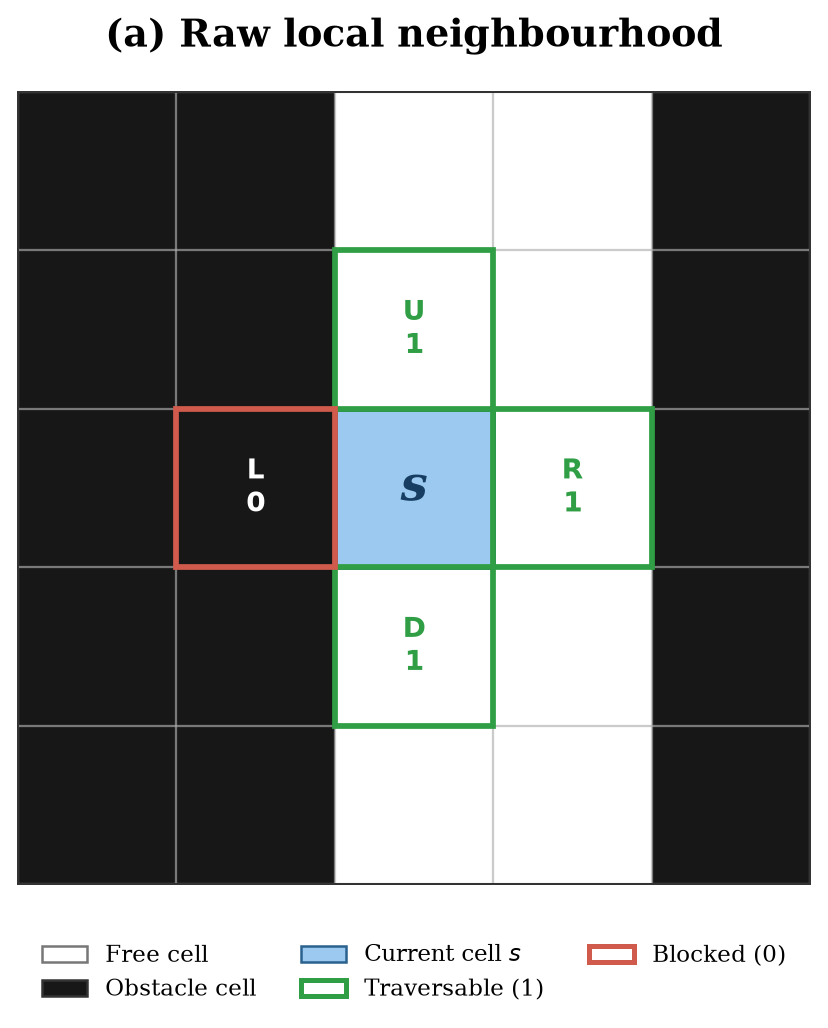

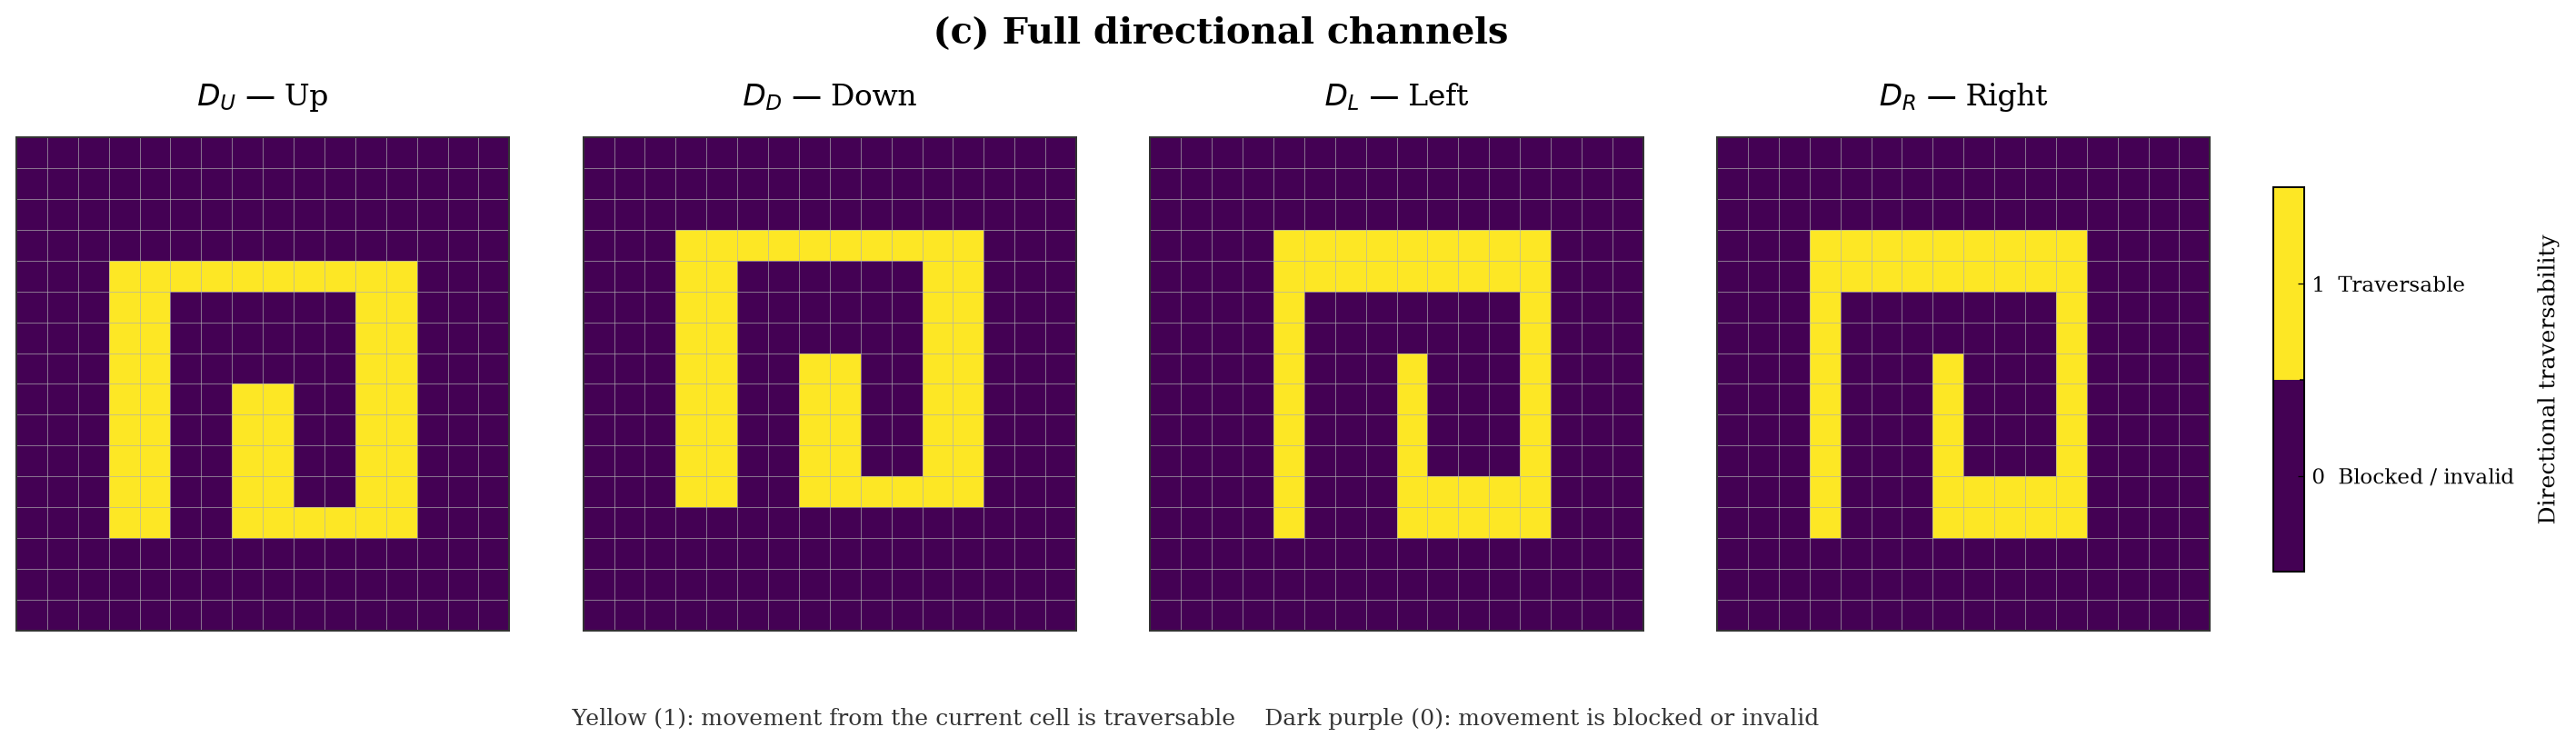

In [3]:
# ============================================================
# 8. Directional Representation Figure
#    Panel (a): Raw local neighbourhood
#    Panel (c): Four directional channels
#
# Reuse map_tensor from the previous code.
# No new maze or map-path pair is generated.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle, Patch
from matplotlib.ticker import FormatStrFormatter

# ------------------------------------------------------------
# 8.1 Construct directional channels
# ------------------------------------------------------------

obstacle_map = map_tensor[0].astype(np.int32)

H, W = obstacle_map.shape

free = (obstacle_map == 0)

# Direction order: Up, Down, Left, Right
directional = np.zeros((4, H, W), dtype=np.int32)

# Up: current cell and cell above must be free
directional[0, 1:, :] = (
    free[1:, :] & free[:-1, :]
).astype(np.int32)

# Down
directional[1, :-1, :] = (
    free[:-1, :] & free[1:, :]
).astype(np.int32)

# Left
directional[2, :, 1:] = (
    free[:, 1:] & free[:, :-1]
).astype(np.int32)

# Right
directional[3, :, :-1] = (
    free[:, :-1] & free[:, 1:]
).astype(np.int32)

D_U, D_D, D_L, D_R = directional

# Final 7-channel representation
directional_representation = np.concatenate(
    [map_tensor, directional],
    axis=0
)

assert directional_representation.shape == (7, H, W)

print("Raw map:", map_tensor.shape)
print("Directional channels:", directional.shape)
print("Final representation:", directional_representation.shape)


# ------------------------------------------------------------
# 8.2 Select a representative cell for Panel (a)
# ------------------------------------------------------------
# Prefer a cell with:
# - exactly 3 traversable directions
# - at least one blocked direction
# - sufficient distance from the outer border
# ------------------------------------------------------------

num_directions = directional.sum(axis=0)

candidates = []

for r in range(2, H - 2):
    for c in range(2, W - 2):

        if obstacle_map[r, c] != 0:
            continue

        if num_directions[r, c] == 3:
            candidates.append((r, c))

# If no 3-direction junction exists, use a 2-direction cell.
if not candidates:

    for r in range(2, H - 2):
        for c in range(2, W - 2):

            if (
                obstacle_map[r, c] == 0
                and num_directions[r, c] == 2
            ):
                candidates.append((r, c))

if not candidates:
    raise RuntimeError(
        "No suitable free cell found for the illustration."
    )

# Deterministic selection
center_r, center_c = candidates[len(candidates) // 2]

local_map = obstacle_map[
    center_r - 2:center_r + 3,
    center_c - 2:center_c + 3
]

local_direction = directional[:, center_r, center_c]

print("Selected cell:", (center_r, center_c))
print(
    "Up, Down, Left, Right:",
    local_direction.tolist()
)


# ------------------------------------------------------------
# 8.3 Plot style
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 6,
    "axes.linewidth": 0.8,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "xtick.direction": "in",
    "ytick.direction": "in",
})

# Raw neighbourhood map style
binary_cmap = ListedColormap([
    "#FFFFFF",  # free
    "#171717"   # obstacle
])

# Directional channels:
# 0 = blocked / invalid -> red
# 1 = traversable       -> green
#direction_cmap = ListedColormap([
#    "#D05B4D",  # red
#    "#2F9E44"   # green
#])

# Directional channels:
# 0 = blocked / invalid -> dark blue
# 1 = traversable       -> bright yellow
direction_cmap = ListedColormap([
    "#440154",  # 0: viridis low endpoint (dark purple-blue)
    "#FDE725"   # 1: viridis high endpoint (yellow)
])

direction_norm = BoundaryNorm(
    [-0.5, 0.5, 1.5],
    direction_cmap.N
)

FREE_COLOR = "#FFFFFF"
OBSTACLE_COLOR = "#171717"
CENTER_COLOR = "#9BC9F0"
VALID_COLOR = "#2F9E44"
BLOCKED_COLOR = "#D05B4D"


# ------------------------------------------------------------
# 8.4 Helper: binary grid drawing
# ------------------------------------------------------------

def draw_binary_grid(
    ax,
    channel,
    cmap,
    norm=None,
    grid_width=0.45
):

    h, w = channel.shape

    ax.imshow(
        channel,
        cmap=cmap,
        norm=norm,
        interpolation="nearest",
        origin="upper"
    )

    ax.set_xticks(
        np.arange(-0.5, w, 1),
        minor=True
    )
    ax.set_yticks(
        np.arange(-0.5, h, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="#AFAFAF",
        linewidth=grid_width,
        alpha=0.65
    )

    ax.set_xticks([])
    ax.set_yticks([])

    ax.tick_params(
        which="both",
        bottom=False,
        left=False
    )

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#333333")

    ax.set_aspect("equal")


# ============================================================
# 8.5 Panel (a): Raw local neighbourhood
# ============================================================

fig_a, ax_a = plt.subplots(
    figsize=(6.5, 6.2),
    dpi=180
)

draw_binary_grid(
    ax_a,
    local_map,
    binary_cmap,
    norm=None,
    grid_width=0.9
)

# Highlight the central free cell
ax_a.add_patch(
    Rectangle(
        (1.5, 1.5),
        1,
        1,
        facecolor=CENTER_COLOR,
        edgecolor="#29618F",
        linewidth=2,
        zorder=3
    )
)

ax_a.text(
    2, 2, "s",
    ha="center",
    va="center",
    fontsize=19,
    fontstyle="italic",
    fontweight="bold",
    color="#173D62",
    zorder=5
)

# Mark four immediate neighbours
neighbours = [
    (1, 2, "U", local_direction[0]),
    (3, 2, "D", local_direction[1]),
    (2, 1, "L", local_direction[2]),
    (2, 3, "R", local_direction[3])
]

for nr, nc, label, valid in neighbours:

    color = VALID_COLOR if valid else BLOCKED_COLOR

    ax_a.add_patch(
        Rectangle(
            (nc - 0.5, nr - 0.5),
            1,
            1,
            facecolor="none",
            edgecolor=color,
            linewidth=2.3,
            zorder=4
        )
    )

    ax_a.text(
        nc, nr,
        f"{label}\n{int(valid)}",
        ha="center",
        va="center",
        fontsize=11,
        fontfamily="DejaVu Sans",
        fontweight="bold",
        color=color if valid else "white",
        zorder=5
    )

ax_a.set_title(
    "(a) Raw local neighbourhood",
    fontsize=15,
    fontweight="bold",
    pad=18
)

legend_handles = [
    Patch(
        facecolor=FREE_COLOR,
        edgecolor="#777777",
        label="Free cell"
    ),
    Patch(
        facecolor=OBSTACLE_COLOR,
        edgecolor="#333333",
        label="Obstacle cell"
    ),
    Patch(
        facecolor=CENTER_COLOR,
        edgecolor="#29618F",
        label="Current cell $s$"
    ),
    Patch(
        facecolor="none",
        edgecolor=VALID_COLOR,
        linewidth=2,
        label="Traversable (1)"
    ),
    Patch(
        facecolor="none",
        edgecolor=BLOCKED_COLOR,
        linewidth=2,
        label="Blocked (0)"
    )
]

ax_a.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=3,
    frameon=False,
    fontsize=9
)

fig_a.subplots_adjust(
    top=0.91,
    bottom=0.20,
    left=0.08,
    right=0.92
)

fig_a.savefig(
    "directional_panel_a.png",
    dpi=300,
    bbox_inches="tight"
)

fig_a.savefig(
    "directional_panel_a.pdf",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 8.6 Panel (c): Four full directional channels
#      Heatmap-style visualisation
# ============================================================

fig_c, axes = plt.subplots(
    1, 4,
    figsize=(15.5, 5.0),
    dpi=180
)

channel_titles = [
    r"$D_U$ — Up",
    r"$D_D$ — Down",
    r"$D_L$ — Left",
    r"$D_R$ — Right"
]

for ax, channel, title in zip(
    axes,
    directional,
    channel_titles
):

    image = ax.imshow(
        channel,
        cmap=direction_cmap,
        norm=direction_norm,
        interpolation="nearest",
        origin="upper"
    )

    # Cell boundaries
    ax.set_xticks(
        np.arange(-0.5, W, 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, H, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="#AFAFAF",
        linewidth=0.4,
        alpha=0.65
    )

    # No numerical values inside cells
    ax.set_xticks([])
    ax.set_yticks([])

    ax.tick_params(
        which="both",
        bottom=False,
        left=False
    )

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#333333")

    ax.set_aspect("equal")

    ax.set_title(
        title,
        fontsize=13,
        pad=14
    )


# ------------------------------------------------------------
# 8.7 Shared colour bar
# ------------------------------------------------------------

cbar_ax = fig_c.add_axes([
    0.915, 0.28, 0.012, 0.47
])

cbar = fig_c.colorbar(
    image,
    cax=cbar_ax,
    ticks=[0, 1]
)

cbar.ax.yaxis.set_major_formatter(
    FormatStrFormatter("%d")
)

cbar.set_label(
    "Directional traversability",
    fontsize=10,
    labelpad=10
)

cbar.ax.set_yticklabels([
    "0  Blocked / invalid",
    "1  Traversable"
])

cbar.ax.tick_params(
    labelsize=9,
    length=3,
    width=0.5
)

cbar.outline.set_linewidth(0.8)


# ------------------------------------------------------------
# 8.8 Title and explanation
# ------------------------------------------------------------
fig_c.suptitle(
    "(c) Full directional channels",
    fontsize=16,
    fontweight="bold",
    y=0.96
)

#fig_c.text(
#    0.49,
#    0.10,
#    "Green (1): movement from the current cell is traversable    "
#    "Red (0): movement is blocked or invalid",
#    ha="center",
#    va="center",
#    fontsize=10,
#    color="#333333"
#)

fig_c.text(
    0.49,
    0.10,
    "Yellow (1): movement from the current cell is traversable    "
    "Dark purple (0): movement is blocked or invalid",
    ha="center",
    va="center",
    fontsize=10,
    color="#333333"
)

fig_c.subplots_adjust(
    left=0.025,
    right=0.89,
    top=0.82,
    bottom=0.20,
    wspace=0.15
)

fig_c.savefig(
    "directional_panel_c.png",
    dpi=300,
    bbox_inches="tight"
)

fig_c.savefig(
    "directional_panel_c.pdf",
    bbox_inches="tight"
)

plt.show()

Loaded file: dataset/pair_00000.npz
Map tensor shape: (3, 64, 64)
Path tensor shape: (1, 64, 64)
Raw map: (3, 64, 64)
Directional channels: (4, 64, 64)
Final representation: (7, 64, 64)
Selected cell: (32, 23)
Up, Down, Left, Right: [1, 1, 0, 1]


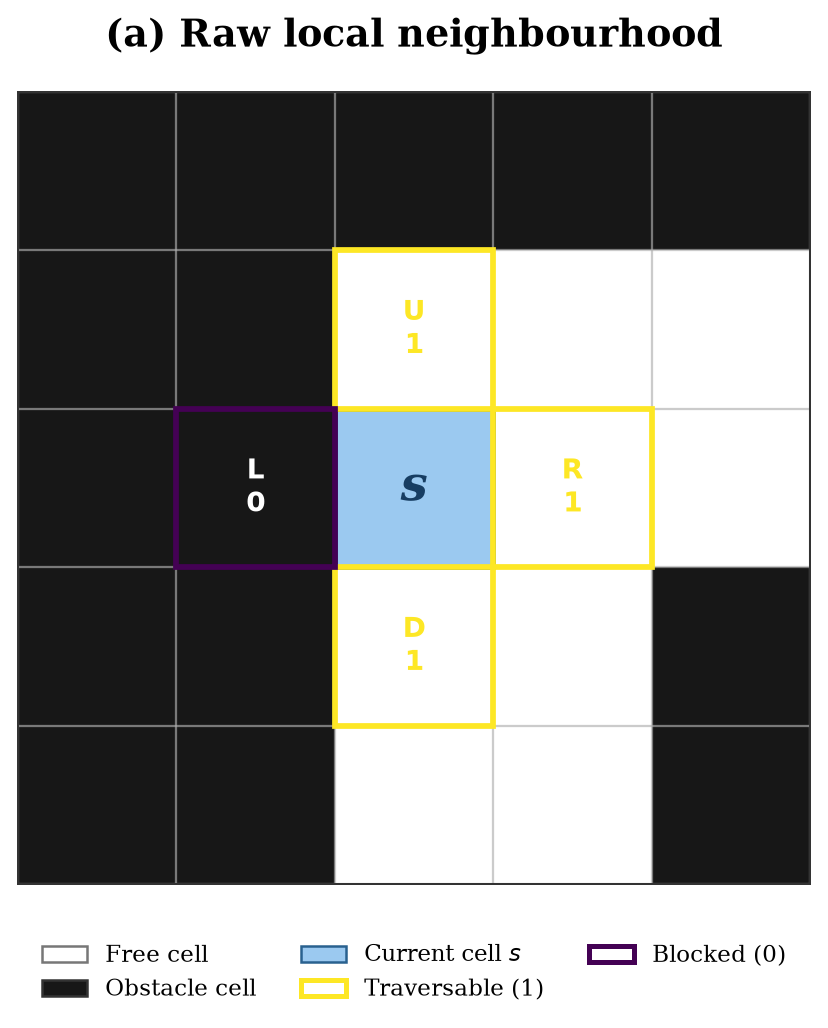

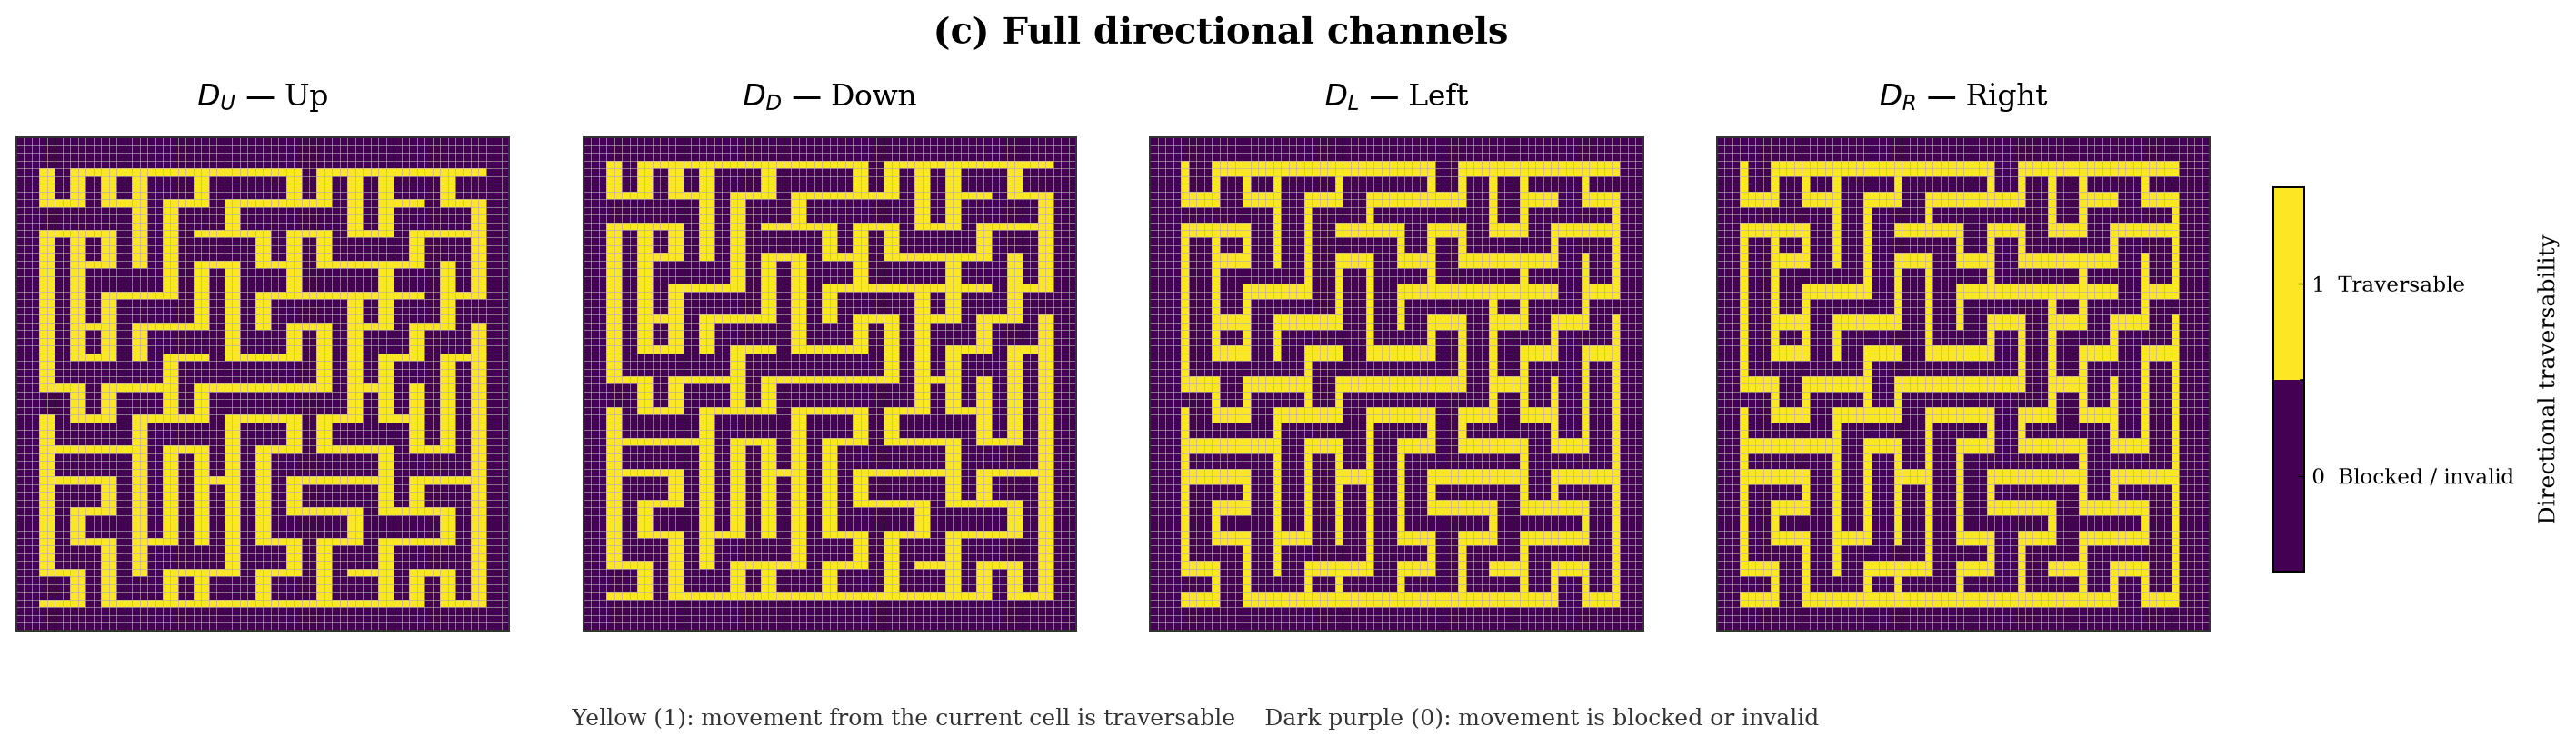

In [4]:
# ============================================================
# 8. Directional Representation Figure
#    Panel (a): Raw local neighbourhood
#    Panel (c): Four directional channels
#
# Standalone version:
# Uses dataset/pair_00000.npz (sample index 0).
# Does not depend on the training notebook or torch.
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle, Patch
from matplotlib.ticker import FormatStrFormatter

# ------------------------------------------------------------
# 8.0 Load map from dataset/pair_00000.npz
# ------------------------------------------------------------

DATASET_DIR = Path("dataset")
SAMPLE_FILE = DATASET_DIR / "pair_00000.npz"

data = np.load(SAMPLE_FILE)

map_tensor = data["map"].astype(np.int32)   # [3, H, W]
path_tensor = data["path"].astype(np.int32) # [1, H, W]

print("Loaded file:", SAMPLE_FILE)
print("Map tensor shape:", map_tensor.shape)
print("Path tensor shape:", path_tensor.shape)

# ------------------------------------------------------------
# 8.1 Construct directional channels
# ------------------------------------------------------------

obstacle_map = map_tensor[0].astype(np.int32)

H, W = obstacle_map.shape

free = (obstacle_map == 0)

# Direction order: Up, Down, Left, Right
directional = np.zeros((4, H, W), dtype=np.int32)

# Up: current cell and cell above must be free
directional[0, 1:, :] = (
    free[1:, :] & free[:-1, :]
).astype(np.int32)

# Down
directional[1, :-1, :] = (
    free[:-1, :] & free[1:, :]
).astype(np.int32)

# Left
directional[2, :, 1:] = (
    free[:, 1:] & free[:, :-1]
).astype(np.int32)

# Right
directional[3, :, :-1] = (
    free[:, :-1] & free[:, 1:]
).astype(np.int32)

D_U, D_D, D_L, D_R = directional

# Final 7-channel representation
directional_representation = np.concatenate(
    [map_tensor, directional],
    axis=0
)

assert directional_representation.shape == (7, H, W)

print("Raw map:", map_tensor.shape)
print("Directional channels:", directional.shape)
print("Final representation:", directional_representation.shape)


# ------------------------------------------------------------
# 8.2 Select a representative cell for Panel (a)
# ------------------------------------------------------------
# Prefer a cell with:
# - exactly 3 traversable directions
# - at least one blocked direction
# - sufficient distance from the outer border
# ------------------------------------------------------------

num_directions = directional.sum(axis=0)

candidates = []

for r in range(2, H - 2):
    for c in range(2, W - 2):

        if obstacle_map[r, c] != 0:
            continue

        if num_directions[r, c] == 3:
            candidates.append((r, c))

# If no 3-direction junction exists, use a 2-direction cell.
if not candidates:

    for r in range(2, H - 2):
        for c in range(2, W - 2):

            if (
                obstacle_map[r, c] == 0
                and num_directions[r, c] == 2
            ):
                candidates.append((r, c))

if not candidates:
    raise RuntimeError(
        "No suitable free cell found for the illustration."
    )

# Deterministic selection
center_r, center_c = candidates[len(candidates) // 2]

local_map = obstacle_map[
    center_r - 2:center_r + 3,
    center_c - 2:center_c + 3
]

local_direction = directional[:, center_r, center_c]

print("Selected cell:", (center_r, center_c))
print(
    "Up, Down, Left, Right:",
    local_direction.tolist()
)


# ------------------------------------------------------------
# 8.3 Plot style
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 6,
    "axes.linewidth": 0.8,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "xtick.direction": "in",
    "ytick.direction": "in",
})

# Raw neighbourhood map style
binary_cmap = ListedColormap([
    "#FFFFFF",  # free
    "#171717"   # obstacle
])

# Directional channels:
# 0 = blocked / invalid -> dark viridis endpoint
# 1 = traversable       -> bright yellow viridis endpoint
direction_cmap = ListedColormap([
    "#440154",  # 0
    "#FDE725"   # 1
])

direction_norm = BoundaryNorm(
    [-0.5, 0.5, 1.5],
    direction_cmap.N
)

FREE_COLOR = "#FFFFFF"
OBSTACLE_COLOR = "#171717"
CENTER_COLOR = "#9BC9F0"
VALID_COLOR = "#FDE725"
BLOCKED_COLOR = "#440154"


# ------------------------------------------------------------
# 8.4 Helper: binary grid drawing
# ------------------------------------------------------------

def draw_binary_grid(
    ax,
    channel,
    cmap,
    norm=None,
    grid_width=0.45
):

    h, w = channel.shape

    ax.imshow(
        channel,
        cmap=cmap,
        norm=norm,
        interpolation="nearest",
        origin="upper"
    )

    ax.set_xticks(
        np.arange(-0.5, w, 1),
        minor=True
    )
    ax.set_yticks(
        np.arange(-0.5, h, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="#AFAFAF",
        linewidth=grid_width,
        alpha=0.65
    )

    ax.set_xticks([])
    ax.set_yticks([])

    ax.tick_params(
        which="both",
        bottom=False,
        left=False
    )

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#333333")

    ax.set_aspect("equal")


# ============================================================
# 8.5 Panel (a): Raw local neighbourhood
# ============================================================

fig_a, ax_a = plt.subplots(
    figsize=(6.5, 6.2),
    dpi=180
)

draw_binary_grid(
    ax_a,
    local_map,
    binary_cmap,
    norm=None,
    grid_width=0.9
)

# Highlight the central free cell
ax_a.add_patch(
    Rectangle(
        (1.5, 1.5),
        1,
        1,
        facecolor=CENTER_COLOR,
        edgecolor="#29618F",
        linewidth=2,
        zorder=3
    )
)

ax_a.text(
    2, 2, "s",
    ha="center",
    va="center",
    fontsize=19,
    fontstyle="italic",
    fontweight="bold",
    color="#173D62",
    zorder=5
)

# Mark four immediate neighbours
neighbours = [
    (1, 2, "U", local_direction[0]),
    (3, 2, "D", local_direction[1]),
    (2, 1, "L", local_direction[2]),
    (2, 3, "R", local_direction[3])
]

for nr, nc, label, valid in neighbours:

    color = VALID_COLOR if valid else BLOCKED_COLOR

    ax_a.add_patch(
        Rectangle(
            (nc - 0.5, nr - 0.5),
            1,
            1,
            facecolor="none",
            edgecolor=color,
            linewidth=2.3,
            zorder=4
        )
    )

    ax_a.text(
        nc, nr,
        f"{label}\n{int(valid)}",
        ha="center",
        va="center",
        fontsize=11,
        fontfamily="DejaVu Sans",
        fontweight="bold",
        color=color if valid else "white",
        zorder=5
    )

ax_a.set_title(
    "(a) Raw local neighbourhood",
    fontsize=15,
    fontweight="bold",
    pad=18
)

legend_handles = [
    Patch(
        facecolor=FREE_COLOR,
        edgecolor="#777777",
        label="Free cell"
    ),
    Patch(
        facecolor=OBSTACLE_COLOR,
        edgecolor="#333333",
        label="Obstacle cell"
    ),
    Patch(
        facecolor=CENTER_COLOR,
        edgecolor="#29618F",
        label="Current cell $s$"
    ),
    Patch(
        facecolor="none",
        edgecolor=VALID_COLOR,
        linewidth=2,
        label="Traversable (1)"
    ),
    Patch(
        facecolor="none",
        edgecolor=BLOCKED_COLOR,
        linewidth=2,
        label="Blocked (0)"
    )
]

ax_a.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=3,
    frameon=False,
    fontsize=9
)

fig_a.subplots_adjust(
    top=0.91,
    bottom=0.20,
    left=0.08,
    right=0.92
)

fig_a.savefig(
    "directional_panel_a.png",
    dpi=300,
    bbox_inches="tight"
)

fig_a.savefig(
    "directional_panel_a.pdf",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 8.6 Panel (c): Four full directional channels
#      Heatmap-style visualisation
# ============================================================

fig_c, axes = plt.subplots(
    1, 4,
    figsize=(15.5, 5.0),
    dpi=180
)

channel_titles = [
    r"$D_U$ — Up",
    r"$D_D$ — Down",
    r"$D_L$ — Left",
    r"$D_R$ — Right"
]

for ax, channel, title in zip(
    axes,
    directional,
    channel_titles
):

    image = ax.imshow(
        channel,
        cmap=direction_cmap,
        norm=direction_norm,
        interpolation="nearest",
        origin="upper"
    )

    # Cell boundaries
    ax.set_xticks(
        np.arange(-0.5, W, 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, H, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="#AFAFAF",
        linewidth=0.4,
        alpha=0.65
    )

    # No numerical values inside cells
    ax.set_xticks([])
    ax.set_yticks([])

    ax.tick_params(
        which="both",
        bottom=False,
        left=False
    )

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#333333")

    ax.set_aspect("equal")

    ax.set_title(
        title,
        fontsize=13,
        pad=14
    )


# ------------------------------------------------------------
# 8.7 Shared colour bar
# ------------------------------------------------------------

cbar_ax = fig_c.add_axes([
    0.915, 0.28, 0.012, 0.47
])

cbar = fig_c.colorbar(
    image,
    cax=cbar_ax,
    ticks=[0, 1]
)

cbar.ax.yaxis.set_major_formatter(
    FormatStrFormatter("%d")
)

cbar.set_label(
    "Directional traversability",
    fontsize=10,
    labelpad=10
)

cbar.ax.set_yticklabels([
    "0  Blocked / invalid",
    "1  Traversable"
])

cbar.ax.tick_params(
    labelsize=9,
    length=3,
    width=0.5
)

cbar.outline.set_linewidth(0.8)


# ------------------------------------------------------------
# 8.8 Title and explanation
# ------------------------------------------------------------

fig_c.suptitle(
    "(c) Full directional channels",
    fontsize=16,
    fontweight="bold",
    y=0.96
)

fig_c.text(
    0.49,
    0.10,
    "Yellow (1): movement from the current cell is traversable    "
    "Dark purple (0): movement is blocked or invalid",
    ha="center",
    va="center",
    fontsize=10,
    color="#333333"
)

fig_c.subplots_adjust(
    left=0.025,
    right=0.89,
    top=0.82,
    bottom=0.20,
    wspace=0.15
)

fig_c.savefig(
    "directional_panel_c.png",
    dpi=300,
    bbox_inches="tight"
)

fig_c.savefig(
    "directional_panel_c.pdf",
    bbox_inches="tight"
)

plt.show()

Raw map: (3, 64, 64)
Directional channels: (4, 64, 64)
Final representation: (7, 64, 64)
Selected cell: (32, 23)
Up, Down, Left, Right: [1, 1, 0, 1]


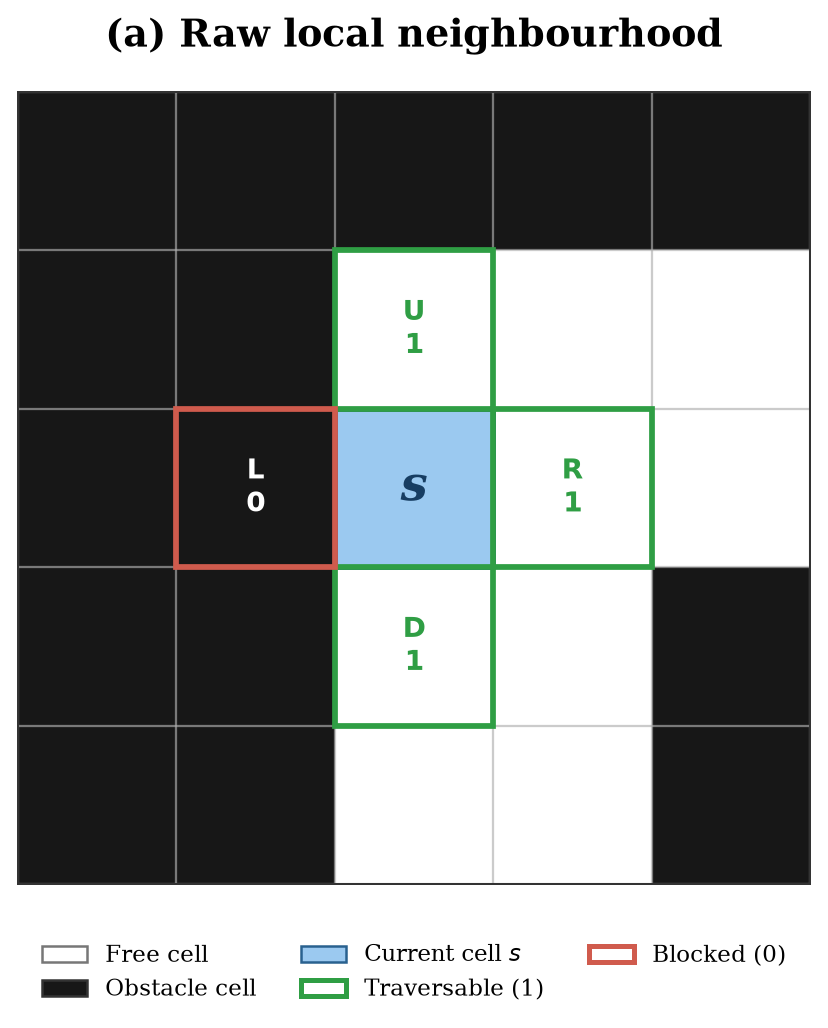

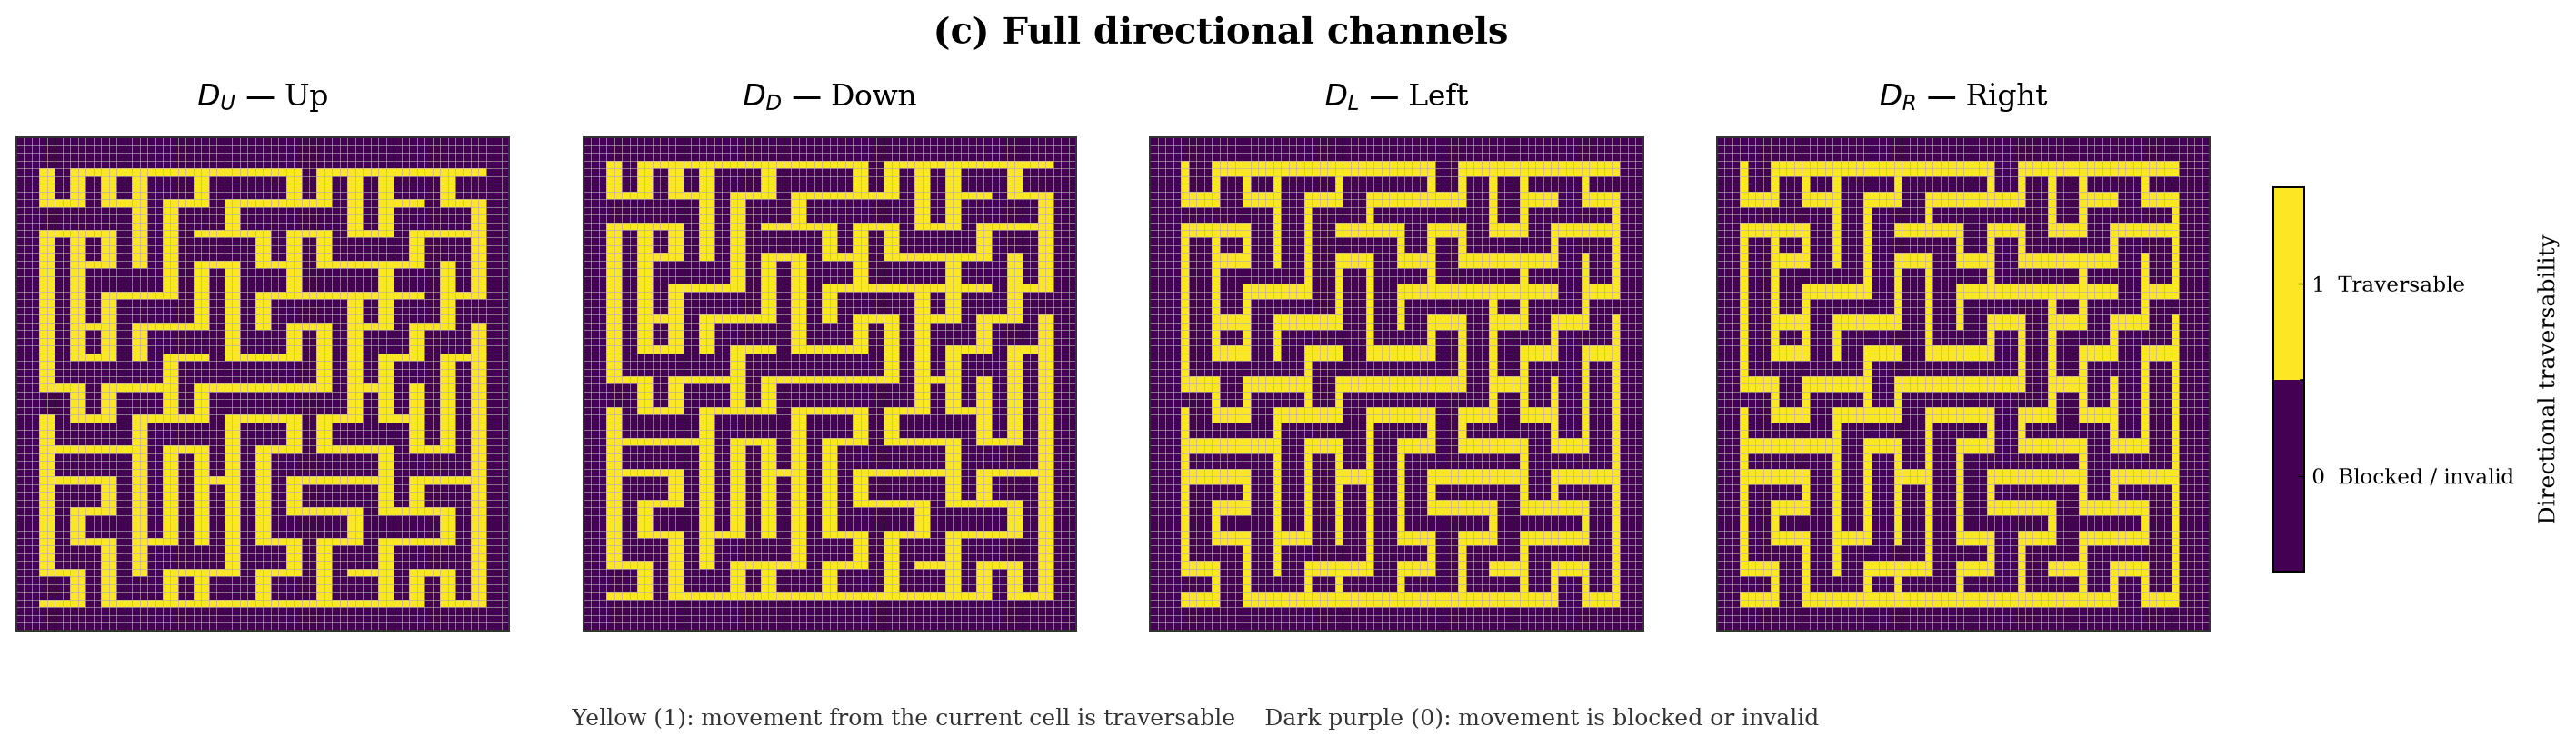

In [1]:
# ============================================================
# 8. Directional Representation Figure
#    Panel (a): Raw local neighbourhood
#    Panel (c): Four directional channels
#
# Load map_tensor from dataset/pair_00000.npz.
# No new maze or map-path pair is generated.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle, Patch
from matplotlib.ticker import FormatStrFormatter


# ------------------------------------------------------------
# 8.0 Load the existing map from the dataset
# ------------------------------------------------------------

DATASET_DIR = Path("dataset")
SAMPLE_FILE = DATASET_DIR / "pair_00000.npz"

with np.load(SAMPLE_FILE, allow_pickle=False) as sample:
    map_key = next(
        (key for key in ("map", "map_tensor", "input_map", "grid")
         if key in sample),
        None
    )

    if map_key is None:
        raise KeyError(
            f"No map array found in {SAMPLE_FILE}. "
            f"Available keys: {sample.files}"
        )

    map_tensor = np.asarray(sample[map_key])

# Convert HWC to CHW if necessary
if (
    map_tensor.ndim == 3
    and map_tensor.shape[-1] == 3
    and map_tensor.shape[0] != 3
):
    map_tensor = np.moveaxis(map_tensor, -1, 0)

if map_tensor.ndim != 3 or map_tensor.shape[0] != 3:
    raise ValueError(
        f"Expected map_tensor shape (3, H, W), "
        f"got {map_tensor.shape}"
    )


# ------------------------------------------------------------
# 8.1 Construct directional channels
# ------------------------------------------------------------

obstacle_map = map_tensor[0].astype(np.int32)

H, W = obstacle_map.shape

free = (obstacle_map == 0)

# Direction order: Up, Down, Left, Right
directional = np.zeros((4, H, W), dtype=np.int32)

# Up: current cell and cell above must be free
directional[0, 1:, :] = (
    free[1:, :] & free[:-1, :]
).astype(np.int32)

# Down
directional[1, :-1, :] = (
    free[:-1, :] & free[1:, :]
).astype(np.int32)

# Left
directional[2, :, 1:] = (
    free[:, 1:] & free[:, :-1]
).astype(np.int32)

# Right
directional[3, :, :-1] = (
    free[:, :-1] & free[:, 1:]
).astype(np.int32)

D_U, D_D, D_L, D_R = directional

# Final 7-channel representation
directional_representation = np.concatenate(
    [map_tensor, directional],
    axis=0
)

assert directional_representation.shape == (7, H, W)

print("Raw map:", map_tensor.shape)
print("Directional channels:", directional.shape)
print("Final representation:", directional_representation.shape)


# ------------------------------------------------------------
# 8.2 Select a representative cell for Panel (a)
# ------------------------------------------------------------
# Prefer a cell with:
# - exactly 3 traversable directions
# - at least one blocked direction
# - sufficient distance from the outer border
# ------------------------------------------------------------

num_directions = directional.sum(axis=0)

candidates = []

for r in range(2, H - 2):
    for c in range(2, W - 2):

        if obstacle_map[r, c] != 0:
            continue

        if num_directions[r, c] == 3:
            candidates.append((r, c))

# If no 3-direction junction exists, use a 2-direction cell.
if not candidates:

    for r in range(2, H - 2):
        for c in range(2, W - 2):

            if (
                obstacle_map[r, c] == 0
                and num_directions[r, c] == 2
            ):
                candidates.append((r, c))

if not candidates:
    raise RuntimeError(
        "No suitable free cell found for the illustration."
    )

# Deterministic selection
center_r, center_c = candidates[len(candidates) // 2]

local_map = obstacle_map[
    center_r - 2:center_r + 3,
    center_c - 2:center_c + 3
]

local_direction = directional[:, center_r, center_c]

print("Selected cell:", (center_r, center_c))
print(
    "Up, Down, Left, Right:",
    local_direction.tolist()
)


# ------------------------------------------------------------
# 8.3 Plot style
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 6,
    "axes.linewidth": 0.8,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "xtick.direction": "in",
    "ytick.direction": "in",
})

# Raw neighbourhood map style
binary_cmap = ListedColormap([
    "#FFFFFF",  # free
    "#171717"   # obstacle
])

# Directional channels:
# 0 = blocked / invalid -> red
# 1 = traversable       -> green
#direction_cmap = ListedColormap([
#    "#D05B4D",  # red
#    "#2F9E44"   # green
#])

# Directional channels:
# 0 = blocked / invalid -> dark blue
# 1 = traversable       -> bright yellow
direction_cmap = ListedColormap([
    "#440154",  # 0: viridis low endpoint (dark purple-blue)
    "#FDE725"   # 1: viridis high endpoint (yellow)
])

direction_norm = BoundaryNorm(
    [-0.5, 0.5, 1.5],
    direction_cmap.N
)

FREE_COLOR = "#FFFFFF"
OBSTACLE_COLOR = "#171717"
CENTER_COLOR = "#9BC9F0"
VALID_COLOR = "#2F9E44"
BLOCKED_COLOR = "#D05B4D"


# ------------------------------------------------------------
# 8.4 Helper: binary grid drawing
# ------------------------------------------------------------

def draw_binary_grid(
    ax,
    channel,
    cmap,
    norm=None,
    grid_width=0.45
):

    h, w = channel.shape

    ax.imshow(
        channel,
        cmap=cmap,
        norm=norm,
        interpolation="nearest",
        origin="upper"
    )

    ax.set_xticks(
        np.arange(-0.5, w, 1),
        minor=True
    )
    ax.set_yticks(
        np.arange(-0.5, h, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="#AFAFAF",
        linewidth=grid_width,
        alpha=0.65
    )

    ax.set_xticks([])
    ax.set_yticks([])

    ax.tick_params(
        which="both",
        bottom=False,
        left=False
    )

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#333333")

    ax.set_aspect("equal")


# ============================================================
# 8.5 Panel (a): Raw local neighbourhood
# ============================================================

fig_a, ax_a = plt.subplots(
    figsize=(6.5, 6.2),
    dpi=180
)

draw_binary_grid(
    ax_a,
    local_map,
    binary_cmap,
    norm=None,
    grid_width=0.9
)

# Highlight the central free cell
ax_a.add_patch(
    Rectangle(
        (1.5, 1.5),
        1,
        1,
        facecolor=CENTER_COLOR,
        edgecolor="#29618F",
        linewidth=2,
        zorder=3
    )
)

ax_a.text(
    2, 2, "s",
    ha="center",
    va="center",
    fontsize=19,
    fontstyle="italic",
    fontweight="bold",
    color="#173D62",
    zorder=5
)

# Mark four immediate neighbours
neighbours = [
    (1, 2, "U", local_direction[0]),
    (3, 2, "D", local_direction[1]),
    (2, 1, "L", local_direction[2]),
    (2, 3, "R", local_direction[3])
]

for nr, nc, label, valid in neighbours:

    color = VALID_COLOR if valid else BLOCKED_COLOR

    ax_a.add_patch(
        Rectangle(
            (nc - 0.5, nr - 0.5),
            1,
            1,
            facecolor="none",
            edgecolor=color,
            linewidth=2.3,
            zorder=4
        )
    )

    ax_a.text(
        nc, nr,
        f"{label}\n{int(valid)}",
        ha="center",
        va="center",
        fontsize=11,
        fontfamily="DejaVu Sans",
        fontweight="bold",
        color=color if valid else "white",
        zorder=5
    )

ax_a.set_title(
    "(a) Raw local neighbourhood",
    fontsize=15,
    fontweight="bold",
    pad=18
)

legend_handles = [
    Patch(
        facecolor=FREE_COLOR,
        edgecolor="#777777",
        label="Free cell"
    ),
    Patch(
        facecolor=OBSTACLE_COLOR,
        edgecolor="#333333",
        label="Obstacle cell"
    ),
    Patch(
        facecolor=CENTER_COLOR,
        edgecolor="#29618F",
        label="Current cell $s$"
    ),
    Patch(
        facecolor="none",
        edgecolor=VALID_COLOR,
        linewidth=2,
        label="Traversable (1)"
    ),
    Patch(
        facecolor="none",
        edgecolor=BLOCKED_COLOR,
        linewidth=2,
        label="Blocked (0)"
    )
]

ax_a.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=3,
    frameon=False,
    fontsize=9
)

fig_a.subplots_adjust(
    top=0.91,
    bottom=0.20,
    left=0.08,
    right=0.92
)

fig_a.savefig(
    "directional_panel_a.png",
    dpi=300,
    bbox_inches="tight"
)

fig_a.savefig(
    "directional_panel_a.pdf",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 8.6 Panel (c): Four full directional channels
#      Heatmap-style visualisation
# ============================================================

fig_c, axes = plt.subplots(
    1, 4,
    figsize=(15.5, 5.0),
    dpi=180
)

channel_titles = [
    r"$D_U$ — Up",
    r"$D_D$ — Down",
    r"$D_L$ — Left",
    r"$D_R$ — Right"
]

for ax, channel, title in zip(
    axes,
    directional,
    channel_titles
):

    image = ax.imshow(
        channel,
        cmap=direction_cmap,
        norm=direction_norm,
        interpolation="nearest",
        origin="upper"
    )

    # Cell boundaries
    ax.set_xticks(
        np.arange(-0.5, W, 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, H, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="#AFAFAF",
        linewidth=0.4,
        alpha=0.65
    )

    # No numerical values inside cells
    ax.set_xticks([])
    ax.set_yticks([])

    ax.tick_params(
        which="both",
        bottom=False,
        left=False
    )

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#333333")

    ax.set_aspect("equal")

    ax.set_title(
        title,
        fontsize=13,
        pad=14
    )


# ------------------------------------------------------------
# 8.7 Shared colour bar
# ------------------------------------------------------------

cbar_ax = fig_c.add_axes([
    0.915, 0.28, 0.012, 0.47
])

cbar = fig_c.colorbar(
    image,
    cax=cbar_ax,
    ticks=[0, 1]
)

cbar.ax.yaxis.set_major_formatter(
    FormatStrFormatter("%d")
)

cbar.set_label(
    "Directional traversability",
    fontsize=10,
    labelpad=10
)

cbar.ax.set_yticklabels([
    "0  Blocked / invalid",
    "1  Traversable"
])

cbar.ax.tick_params(
    labelsize=9,
    length=3,
    width=0.5
)

cbar.outline.set_linewidth(0.8)


# ------------------------------------------------------------
# 8.8 Title and explanation
# ------------------------------------------------------------

fig_c.suptitle(
    "(c) Full directional channels",
    fontsize=16,
    fontweight="bold",
    y=0.96
)

#fig_c.text(
#    0.49,
#    0.10,
#    "Green (1): movement from the current cell is traversable    "
#    "Red (0): movement is blocked or invalid",
#    ha="center",
#    va="center",
#    fontsize=10,
#    color="#333333"
#)

fig_c.text(
    0.49,
    0.10,
    "Yellow (1): movement from the current cell is traversable    "
    "Dark purple (0): movement is blocked or invalid",
    ha="center",
    va="center",
    fontsize=10,
    color="#333333"
)

fig_c.subplots_adjust(
    left=0.025,
    right=0.89,
    top=0.82,
    bottom=0.20,
    wspace=0.15
)

fig_c.savefig(
    "directional_panel_c.png",
    dpi=300,
    bbox_inches="tight"
)

fig_c.savefig(
    "directional_panel_c.pdf",
    bbox_inches="tight"
)

plt.show()

Raw map: (3, 16, 16)
Boundary channels: (4, 16, 16)
Final representation: (7, 16, 16)
Normalization factor: 15.0
Maximum normalized value: 0.6


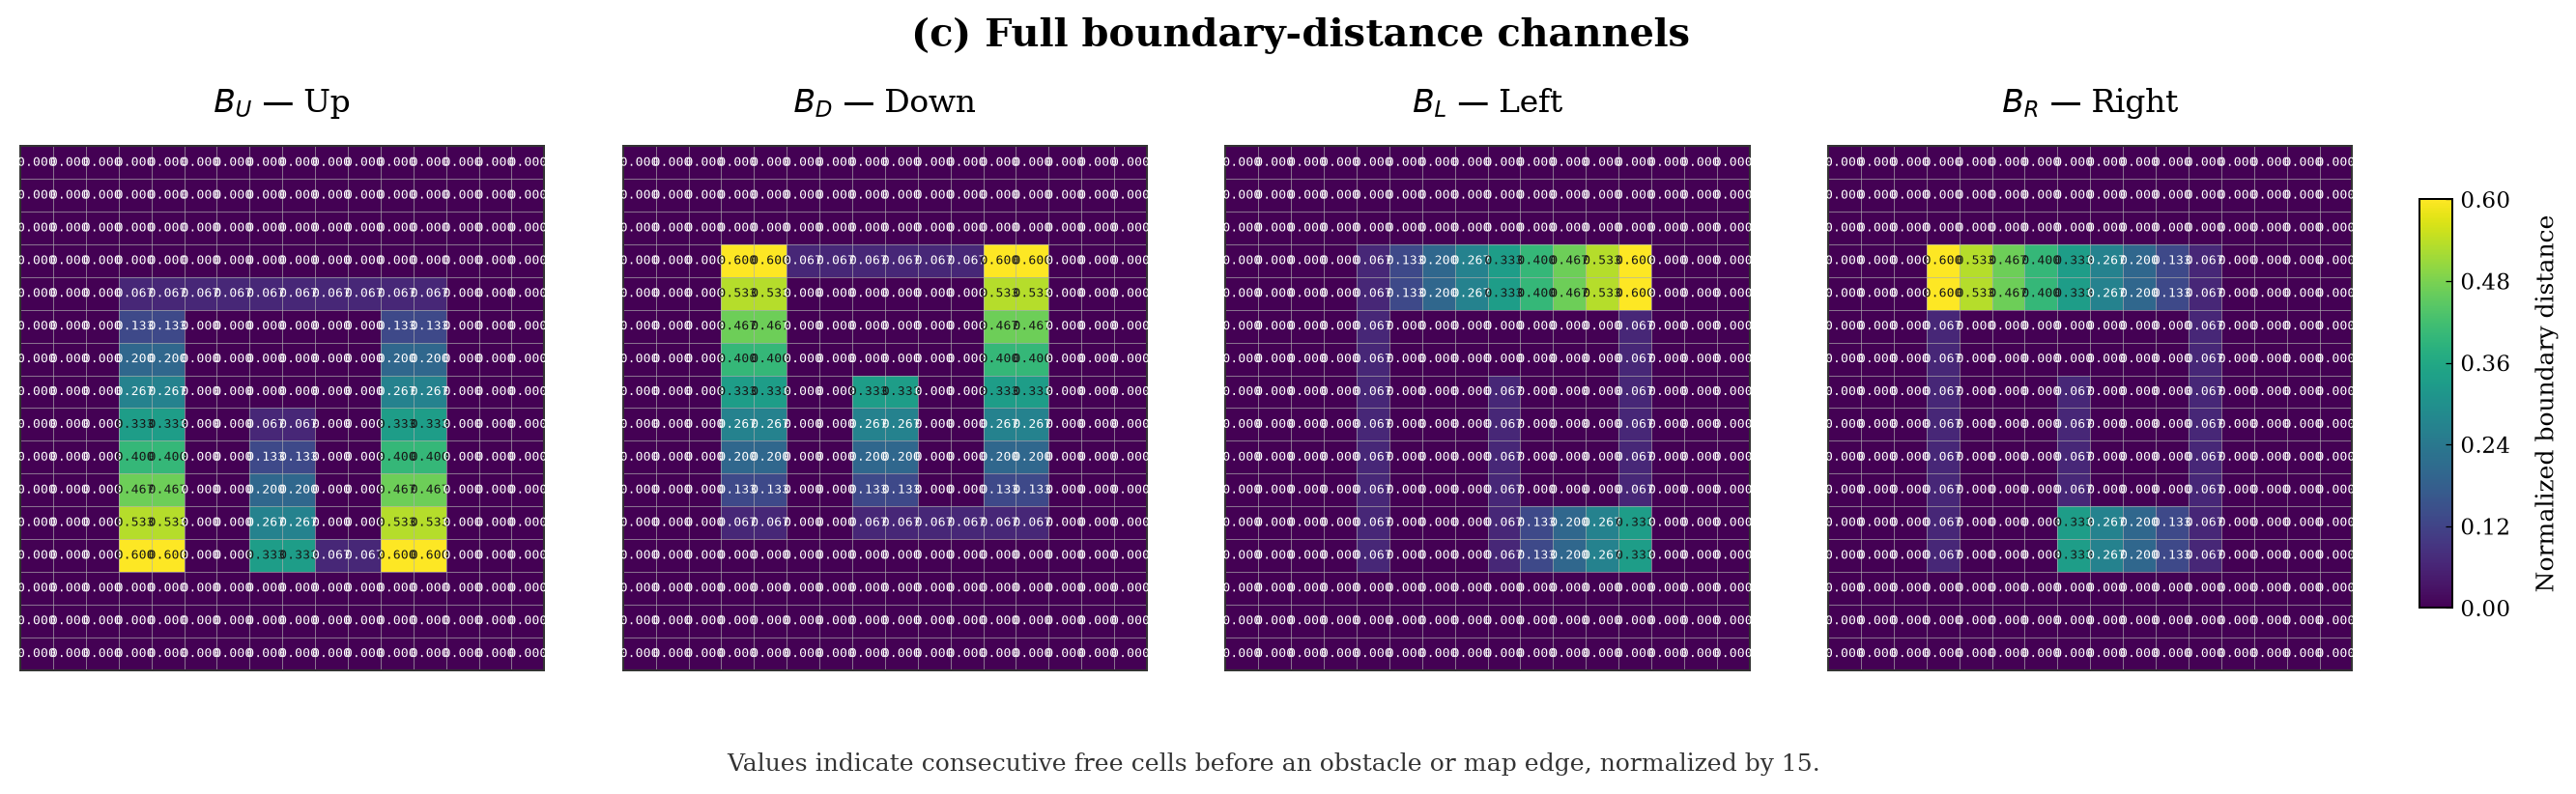

In [5]:
# ============================================================
# 9. Boundary-Distance Representation Figure
#    Panel (c): Four full boundary-distance channels
#
# Reuse map_tensor from the previous code.
# No new maze or map-path pair is generated.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

# ------------------------------------------------------------
# 9.1 Construct boundary-distance channels
# ------------------------------------------------------------
# Direction order: Up, Down, Left, Right
# Count consecutive free cells before the first obstacle
# or map edge, excluding the current cell.
#
# Normalize by max spatial displacement:
# 16x16 -> 15
# 64x64 -> 63
# ------------------------------------------------------------

obstacle_map = np.asarray(map_tensor[0])

H, W = obstacle_map.shape
blocked = obstacle_map > 0.5

up = np.zeros((H, W), dtype=np.float32)
down = np.zeros((H, W), dtype=np.float32)
left = np.zeros((H, W), dtype=np.float32)
right = np.zeros((H, W), dtype=np.float32)

# Up
for c in range(W):
    run = 0
    for r in range(H):
        if blocked[r, c]:
            run = 0
        else:
            up[r, c] = run
            run += 1

# Down
for c in range(W):
    run = 0
    for r in range(H - 1, -1, -1):
        if blocked[r, c]:
            run = 0
        else:
            down[r, c] = run
            run += 1

# Left
for r in range(H):
    run = 0
    for c in range(W):
        if blocked[r, c]:
            run = 0
        else:
            left[r, c] = run
            run += 1

# Right
for r in range(H):
    run = 0
    for c in range(W - 1, -1, -1):
        if blocked[r, c]:
            run = 0
        else:
            right[r, c] = run
            run += 1

normalizer = float(max(H - 1, W - 1, 1))

boundary = np.stack(
    [up, down, left, right],
    axis=0
) / normalizer

B_U, B_D, B_L, B_R = boundary

# Final 7-channel representation
boundary_representation = np.concatenate(
    [map_tensor.astype(np.float32), boundary],
    axis=0
)

assert boundary_representation.shape == (7, H, W)

print("Raw map:", map_tensor.shape)
print("Boundary channels:", boundary.shape)
print("Final representation:", boundary_representation.shape)
print("Normalization factor:", normalizer)
print("Maximum normalized value:", boundary.max())


# ------------------------------------------------------------
# 9.2 Plot style (consistent with previous figures)
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 6,
    "axes.linewidth": 0.8,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "xtick.direction": "in",
    "ytick.direction": "in",
})

# Heatmap colour scale
HEATMAP_CMAP = "viridis"

# True normalized range is [0, 1].
# Choose "observed" for better contrast in the 16x16 maze.
# Choose "full" for a fixed 0-1 scale.
COLOR_SCALE = "observed"

vmin = 0.0
vmax = (
    1.0 if COLOR_SCALE == "full"
    else max(float(boundary.max()), 1e-6)
)


# ------------------------------------------------------------
# 9.3 Plot four boundary-distance channels
# ------------------------------------------------------------

fig_b, axes = plt.subplots(
    1, 4,
    figsize=(15.5, 5.0),
    dpi=180
)

channel_titles = [
    r"$B_U$ — Up",
    r"$B_D$ — Down",
    r"$B_L$ — Left",
    r"$B_R$ — Right"
]

for ax, channel, title in zip(
    axes,
    boundary,
    channel_titles
):

    image = ax.imshow(
        channel,
        cmap=HEATMAP_CMAP,
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest",
        origin="upper"
    )

    # Cell boundaries
    ax.set_xticks(
        np.arange(-0.5, W, 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, H, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="#AFAFAF",
        linewidth=0.4,
        alpha=0.65
    )

    # Normalized numerical values in each cell
    for r in range(H):
        for c in range(W):

            value = float(channel[r, c])

            # Use contrasting text for readability
            norm_value = value / vmax
            text_color = (
                "#FFFFFF" if norm_value < 0.48
                else "#171717"
            )

            ax.text(
                c,
                r,
                f"{value:.3f}",
                ha="center",
                va="center",
                fontsize=5.3,
                fontfamily="DejaVu Sans Mono",
                color=text_color
            )

    ax.set_xticks([])
    ax.set_yticks([])

    ax.tick_params(
        which="both",
        bottom=False,
        left=False
    )

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#333333")

    ax.set_aspect("equal")

    ax.set_title(
        title,
        fontsize=13,
        pad=14
    )


# ------------------------------------------------------------
# 9.4 Shared colour bar
# ------------------------------------------------------------

cbar_ax = fig_b.add_axes([
    0.915, 0.28, 0.012, 0.47
])

cbar = fig_b.colorbar(
    image,
    cax=cbar_ax,
    ticks=np.linspace(0, vmax, 6)
)

cbar.ax.yaxis.set_major_formatter(
    FormatStrFormatter("%.2f")
)

cbar.set_label(
    "Normalized boundary distance",
    fontsize=10,
    labelpad=10
)

cbar.ax.tick_params(
    labelsize=9,
    length=3,
    width=0.5
)

cbar.outline.set_linewidth(0.8)


# ------------------------------------------------------------
# 9.5 Title and explanation
# ------------------------------------------------------------

fig_b.suptitle(
    "(c) Full boundary-distance channels",
    fontsize=16,
    fontweight="bold",
    y=0.96
)

fig_b.text(
    0.49,
    0.10,
    "Values indicate consecutive free cells before an "
    "obstacle or map edge, normalized by "
    f"{int(normalizer)}.",
    ha="center",
    va="center",
    fontsize=10,
    color="#333333"
)

fig_b.subplots_adjust(
    left=0.025,
    right=0.89,
    top=0.82,
    bottom=0.20,
    wspace=0.15
)


# ------------------------------------------------------------
# 9.6 Save
# ------------------------------------------------------------

fig_b.savefig(
    "boundary_panel_c.png",
    dpi=300,
    bbox_inches="tight"
)

fig_b.savefig(
    "boundary_panel_c.pdf",
    bbox_inches="tight"
)

plt.show()

Raw map: (3, 16, 16)
Boundary channels: (4, 16, 16)
Final representation: (7, 16, 16)
Normalization factor: 15.0
Maximum normalized value: 0.6


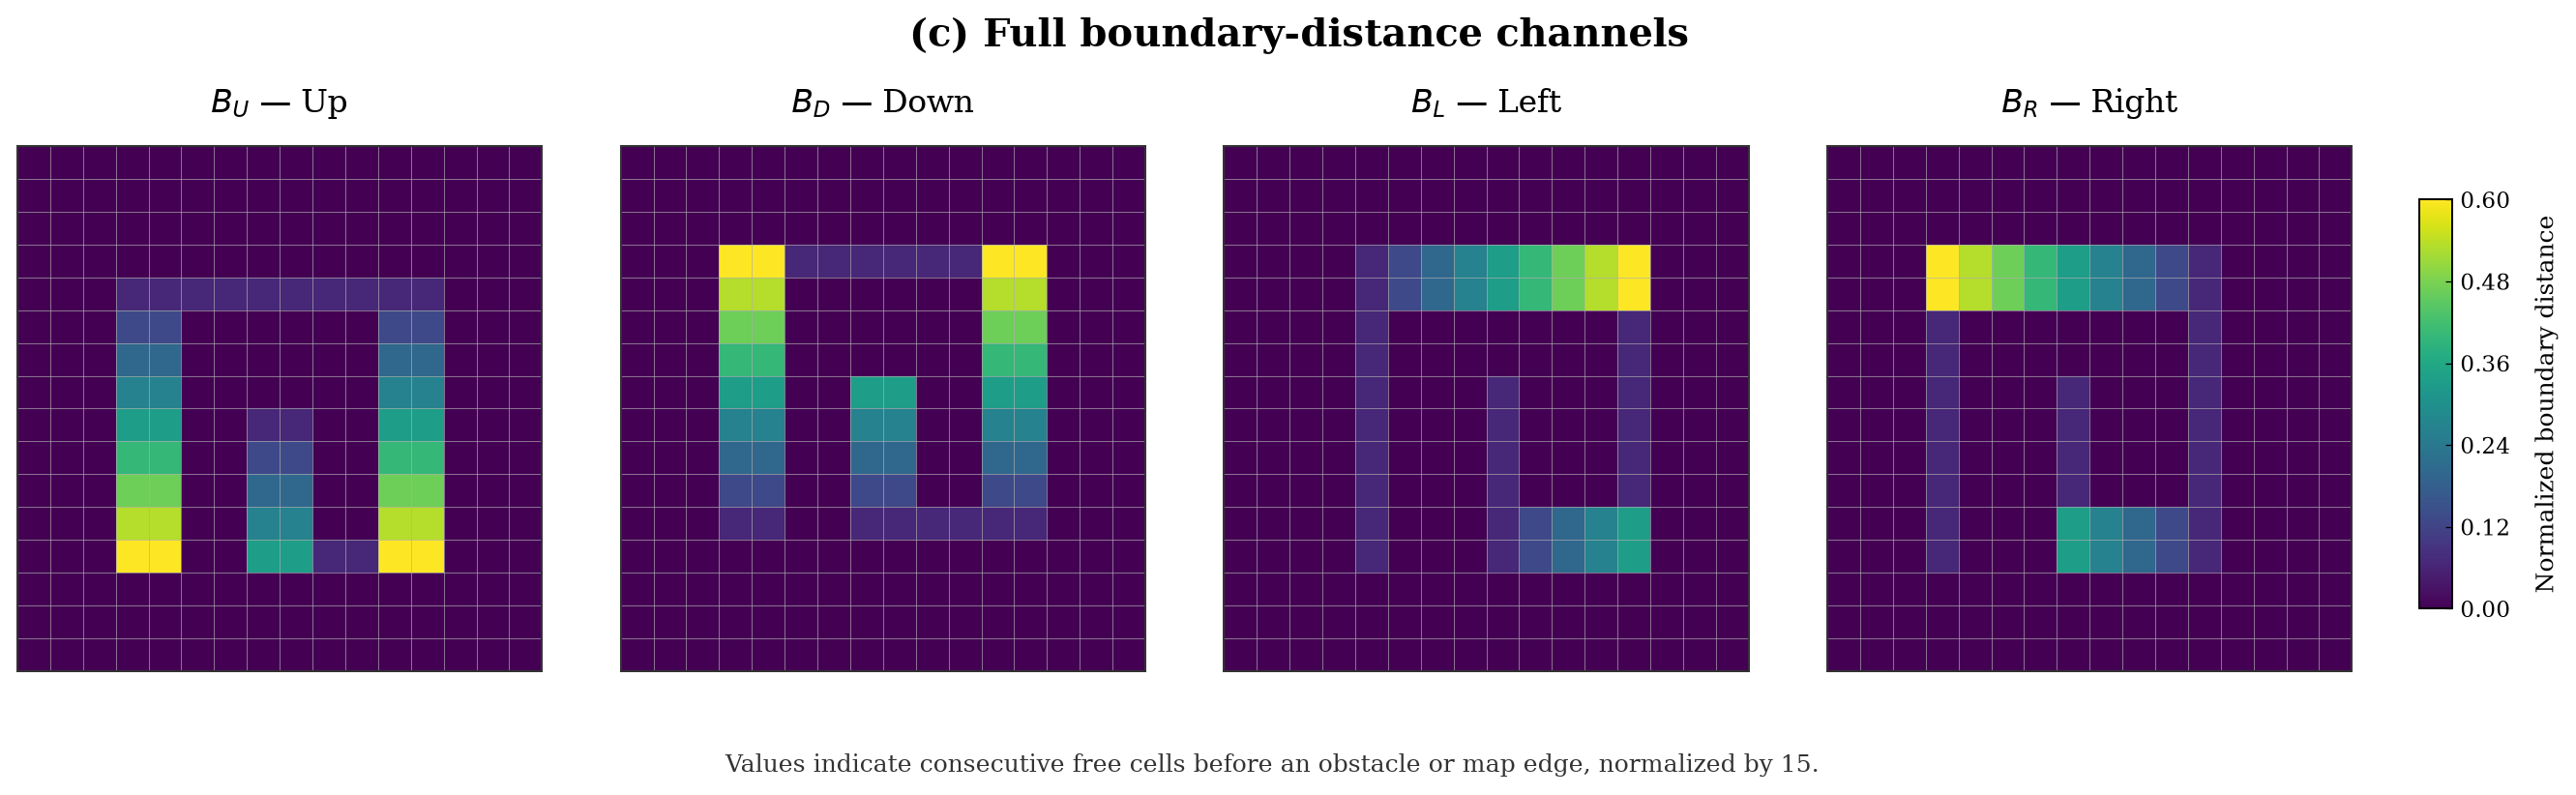

In [6]:
# ============================================================
# 9. Boundary-Distance Representation Figure
#    Panel (c): Four full boundary-distance channels
#
# Reuse map_tensor from the previous code.
# No new maze or map-path pair is generated.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

# ------------------------------------------------------------
# 9.1 Construct boundary-distance channels
# ------------------------------------------------------------
# Direction order: Up, Down, Left, Right
# Count consecutive free cells before the first obstacle
# or map edge, excluding the current cell.
#
# Normalize by max spatial displacement:
# 16x16 -> 15
# 64x64 -> 63
# ------------------------------------------------------------

obstacle_map = np.asarray(map_tensor[0])

H, W = obstacle_map.shape
blocked = obstacle_map > 0.5

up = np.zeros((H, W), dtype=np.float32)
down = np.zeros((H, W), dtype=np.float32)
left = np.zeros((H, W), dtype=np.float32)
right = np.zeros((H, W), dtype=np.float32)

# Up
for c in range(W):
    run = 0
    for r in range(H):
        if blocked[r, c]:
            run = 0
        else:
            up[r, c] = run
            run += 1

# Down
for c in range(W):
    run = 0
    for r in range(H - 1, -1, -1):
        if blocked[r, c]:
            run = 0
        else:
            down[r, c] = run
            run += 1

# Left
for r in range(H):
    run = 0
    for c in range(W):
        if blocked[r, c]:
            run = 0
        else:
            left[r, c] = run
            run += 1

# Right
for r in range(H):
    run = 0
    for c in range(W - 1, -1, -1):
        if blocked[r, c]:
            run = 0
        else:
            right[r, c] = run
            run += 1

normalizer = float(max(H - 1, W - 1, 1))

boundary = np.stack(
    [up, down, left, right],
    axis=0
) / normalizer

B_U, B_D, B_L, B_R = boundary

# Final 7-channel representation
boundary_representation = np.concatenate(
    [map_tensor.astype(np.float32), boundary],
    axis=0
)

assert boundary_representation.shape == (7, H, W)

print("Raw map:", map_tensor.shape)
print("Boundary channels:", boundary.shape)
print("Final representation:", boundary_representation.shape)
print("Normalization factor:", normalizer)
print("Maximum normalized value:", boundary.max())


# ------------------------------------------------------------
# 9.2 Plot style (consistent with previous figures)
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 6,
    "axes.linewidth": 0.8,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "xtick.direction": "in",
    "ytick.direction": "in",
})

# Heatmap colour scale
HEATMAP_CMAP = "viridis"

# True normalized range is [0, 1].
# Choose "observed" for better contrast in the 16x16 maze.
# Choose "full" for a fixed 0-1 scale.
COLOR_SCALE = "observed"

vmin = 0.0
vmax = (
    1.0 if COLOR_SCALE == "full"
    else max(float(boundary.max()), 1e-6)
)


# ------------------------------------------------------------
# 9.3 Plot four boundary-distance channels
# ------------------------------------------------------------

fig_b, axes = plt.subplots(
    1, 4,
    figsize=(15.5, 5.0),
    dpi=180
)

channel_titles = [
    r"$B_U$ — Up",
    r"$B_D$ — Down",
    r"$B_L$ — Left",
    r"$B_R$ — Right"
]

for ax, channel, title in zip(
    axes,
    boundary,
    channel_titles
):

    image = ax.imshow(
        channel,
        cmap=HEATMAP_CMAP,
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest",
        origin="upper"
    )

    # Cell boundaries
    ax.set_xticks(
        np.arange(-0.5, W, 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, H, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="#AFAFAF",
        linewidth=0.4,
        alpha=0.65
    )

    # No numerical values inside cells
    ax.set_xticks([])
    ax.set_yticks([])

    ax.tick_params(
        which="both",
        bottom=False,
        left=False
    )

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#333333")

    ax.set_aspect("equal")

    ax.set_title(
        title,
        fontsize=13,
        pad=14
    )


# ------------------------------------------------------------
# 9.4 Shared colour bar
# ------------------------------------------------------------

cbar_ax = fig_b.add_axes([
    0.915, 0.28, 0.012, 0.47
])

cbar = fig_b.colorbar(
    image,
    cax=cbar_ax,
    ticks=np.linspace(0, vmax, 6)
)

cbar.ax.yaxis.set_major_formatter(
    FormatStrFormatter("%.2f")
)

cbar.set_label(
    "Normalized boundary distance",
    fontsize=10,
    labelpad=10
)

cbar.ax.tick_params(
    labelsize=9,
    length=3,
    width=0.5
)

cbar.outline.set_linewidth(0.8)


# ------------------------------------------------------------
# 9.5 Title and explanation
# ------------------------------------------------------------

fig_b.suptitle(
    "(c) Full boundary-distance channels",
    fontsize=16,
    fontweight="bold",
    y=0.96
)

fig_b.text(
    0.49,
    0.10,
    "Values indicate consecutive free cells before an "
    "obstacle or map edge, normalized by "
    f"{int(normalizer)}.",
    ha="center",
    va="center",
    fontsize=10,
    color="#333333"
)

fig_b.subplots_adjust(
    left=0.025,
    right=0.89,
    top=0.82,
    bottom=0.20,
    wspace=0.15
)


# ------------------------------------------------------------
# 9.6 Save
# ------------------------------------------------------------

fig_b.savefig(
    "boundary_panel_c.png",
    dpi=300,
    bbox_inches="tight"
)

fig_b.savefig(
    "boundary_panel_c.pdf",
    bbox_inches="tight"
)

plt.show()

Loaded file: dataset/pair_00000.npz
Map tensor shape: (3, 64, 64)
Raw map: (3, 64, 64)
Boundary channels: (4, 64, 64)
Final representation: (7, 64, 64)
Normalization factor: 63.0
Maximum normalized value: 0.6507937


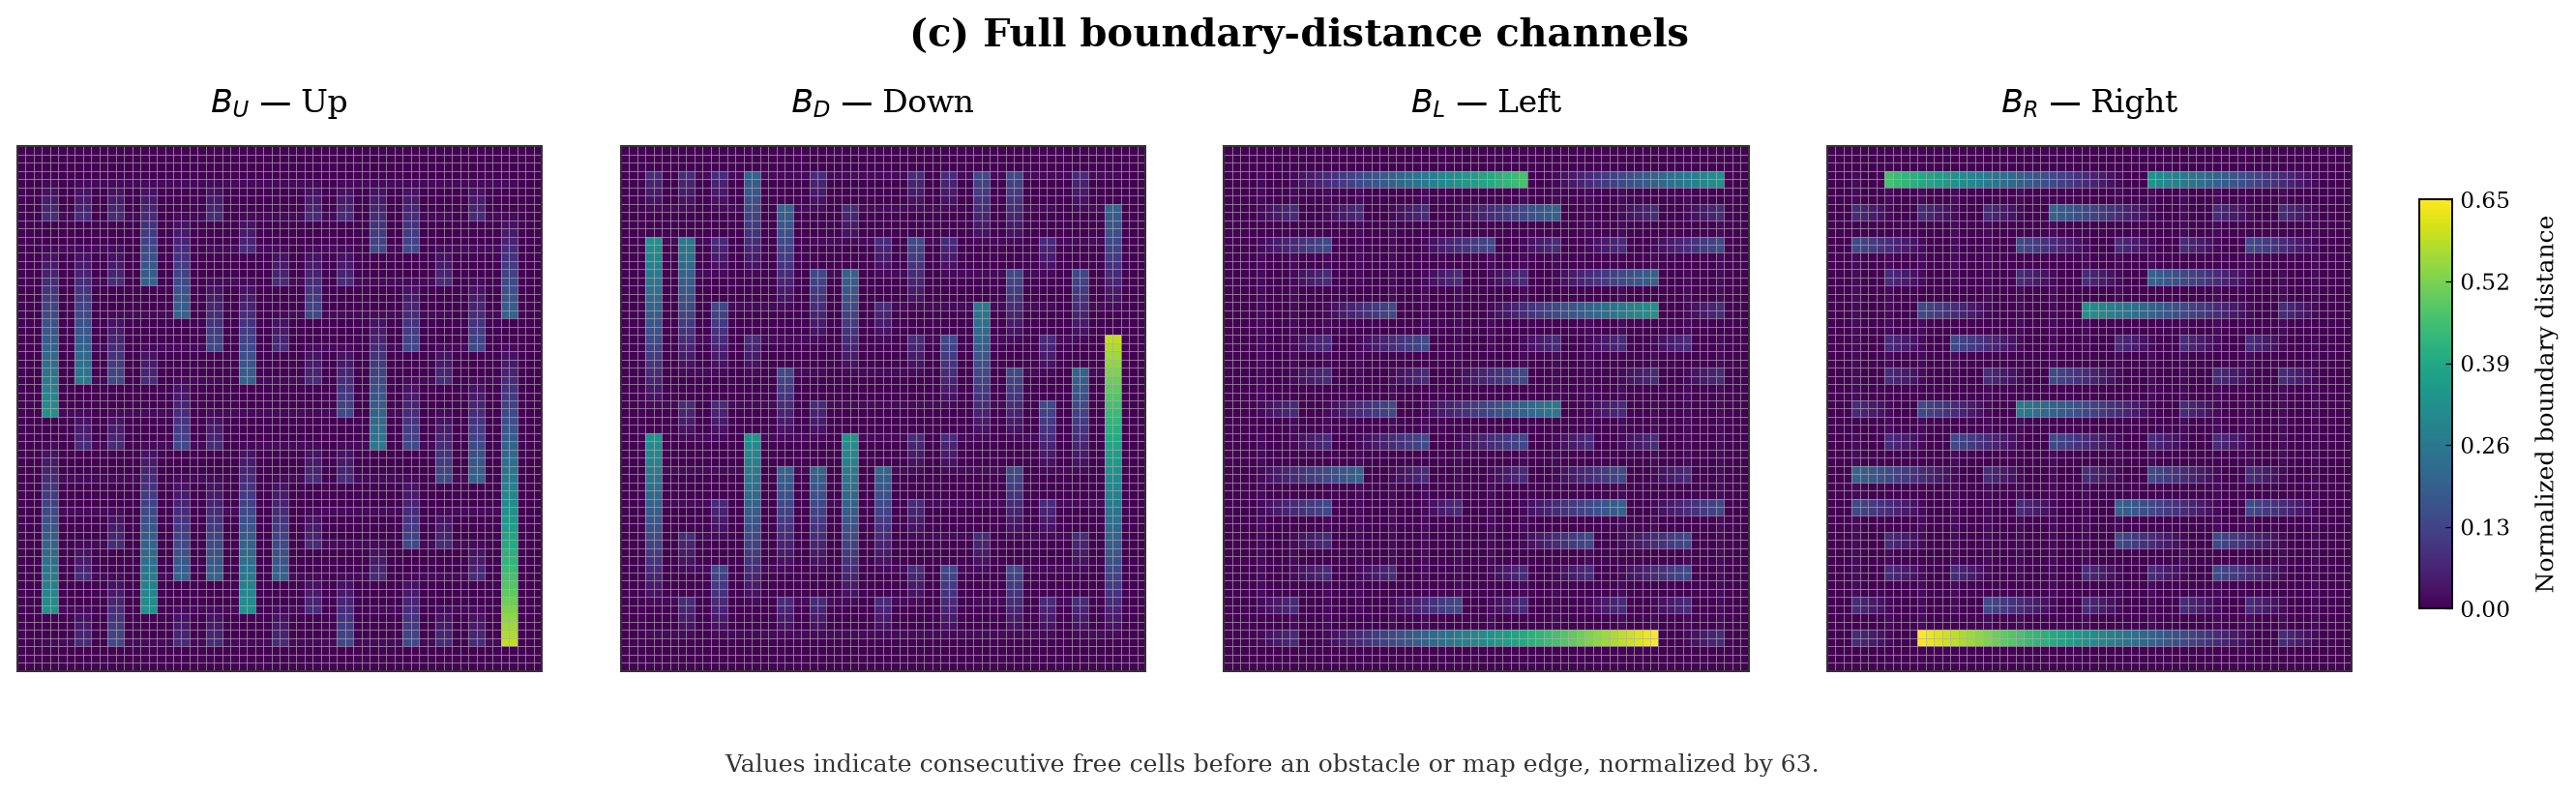

In [5]:

# ============================================================
# 9. Boundary-Distance Representation Figure
#    Panel (c): Four full boundary-distance channels
#
# Standalone version:
# Uses dataset/pair_00000.npz (sample index 0).
# No new maze or map-path pair is generated.
# Does not depend on previous notebook cells or torch.
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter


# ------------------------------------------------------------
# 9.0 Load map from dataset/pair_00000.npz
# ------------------------------------------------------------

DATASET_DIR = Path("dataset")
SAMPLE_FILE = DATASET_DIR / "pair_00000.npz"

data = np.load(SAMPLE_FILE)

map_tensor = data["map"].astype(np.float32)  # [3, H, W]

print("Loaded file:", SAMPLE_FILE)
print("Map tensor shape:", map_tensor.shape)


# ------------------------------------------------------------
# 9.1 Construct boundary-distance channels
# ------------------------------------------------------------
# Direction order: Up, Down, Left, Right
# Count consecutive free cells before the first obstacle
# or map edge, excluding the current cell.
#
# Normalize by max spatial displacement:
# 16x16 -> 15
# 64x64 -> 63
# ------------------------------------------------------------

obstacle_map = np.asarray(map_tensor[0])

H, W = obstacle_map.shape
blocked = obstacle_map > 0.5

up = np.zeros((H, W), dtype=np.float32)
down = np.zeros((H, W), dtype=np.float32)
left = np.zeros((H, W), dtype=np.float32)
right = np.zeros((H, W), dtype=np.float32)

# Up
for c in range(W):
    run = 0
    for r in range(H):
        if blocked[r, c]:
            run = 0
        else:
            up[r, c] = run
            run += 1

# Down
for c in range(W):
    run = 0
    for r in range(H - 1, -1, -1):
        if blocked[r, c]:
            run = 0
        else:
            down[r, c] = run
            run += 1

# Left
for r in range(H):
    run = 0
    for c in range(W):
        if blocked[r, c]:
            run = 0
        else:
            left[r, c] = run
            run += 1

# Right
for r in range(H):
    run = 0
    for c in range(W - 1, -1, -1):
        if blocked[r, c]:
            run = 0
        else:
            right[r, c] = run
            run += 1

normalizer = float(max(H - 1, W - 1, 1))

boundary = np.stack(
    [up, down, left, right],
    axis=0
) / normalizer

B_U, B_D, B_L, B_R = boundary

# Final 7-channel representation
boundary_representation = np.concatenate(
    [map_tensor.astype(np.float32), boundary],
    axis=0
)

assert boundary_representation.shape == (7, H, W)

print("Raw map:", map_tensor.shape)
print("Boundary channels:", boundary.shape)
print("Final representation:", boundary_representation.shape)
print("Normalization factor:", normalizer)
print("Maximum normalized value:", boundary.max())


# ------------------------------------------------------------
# 9.2 Plot style (consistent with previous figures)
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 6,
    "axes.linewidth": 0.8,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "xtick.direction": "in",
    "ytick.direction": "in",
})

# Heatmap colour scale
HEATMAP_CMAP = "viridis"

# True normalized range is [0, 1].
# Choose "observed" for better contrast in the 16x16 maze.
# Choose "full" for a fixed 0-1 scale.
COLOR_SCALE = "observed"

vmin = 0.0
vmax = (
    1.0 if COLOR_SCALE == "full"
    else max(float(boundary.max()), 1e-6)
)


# ------------------------------------------------------------
# 9.3 Plot four boundary-distance channels
# ------------------------------------------------------------

fig_b, axes = plt.subplots(
    1, 4,
    figsize=(15.5, 5.0),
    dpi=180
)

channel_titles = [
    r"$B_U$ — Up",
    r"$B_D$ — Down",
    r"$B_L$ — Left",
    r"$B_R$ — Right"
]

for ax, channel, title in zip(
    axes,
    boundary,
    channel_titles
):

    image = ax.imshow(
        channel,
        cmap=HEATMAP_CMAP,
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest",
        origin="upper"
    )

    # Cell boundaries
    ax.set_xticks(
        np.arange(-0.5, W, 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, H, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="#AFAFAF",
        linewidth=0.4,
        alpha=0.65
    )

    # No numerical values inside cells
    ax.set_xticks([])
    ax.set_yticks([])

    ax.tick_params(
        which="both",
        bottom=False,
        left=False
    )

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#333333")

    ax.set_aspect("equal")

    ax.set_title(
        title,
        fontsize=13,
        pad=14
    )


# ------------------------------------------------------------
# 9.4 Shared colour bar
# ------------------------------------------------------------

cbar_ax = fig_b.add_axes([
    0.915, 0.28, 0.012, 0.47
])

cbar = fig_b.colorbar(
    image,
    cax=cbar_ax,
    ticks=np.linspace(0, vmax, 6)
)

cbar.ax.yaxis.set_major_formatter(
    FormatStrFormatter("%.2f")
)

cbar.set_label(
    "Normalized boundary distance",
    fontsize=10,
    labelpad=10
)

cbar.ax.tick_params(
    labelsize=9,
    length=3,
    width=0.5
)

cbar.outline.set_linewidth(0.8)


# ------------------------------------------------------------
# 9.5 Title and explanation
# ------------------------------------------------------------

fig_b.suptitle(
    "(c) Full boundary-distance channels",
    fontsize=16,
    fontweight="bold",
    y=0.96
)

fig_b.text(
    0.49,
    0.10,
    "Values indicate consecutive free cells before an "
    "obstacle or map edge, normalized by "
    f"{int(normalizer)}.",
    ha="center",
    va="center",
    fontsize=10,
    color="#333333"
)

fig_b.subplots_adjust(
    left=0.025,
    right=0.89,
    top=0.82,
    bottom=0.20,
    wspace=0.15
)


# ------------------------------------------------------------
# 9.6 Save
# ------------------------------------------------------------

fig_b.savefig(
    "boundary_panel_c.png",
    dpi=300,
    bbox_inches="tight"
)

fig_b.savefig(
    "boundary_panel_c.pdf",
    bbox_inches="tight"
)

plt.show()


In [12]:
# ============================================================
# Topological Landmark Representation Figure — Standalone
# Uses dataset/pair_00000.npz (sample index 0).
# Does not depend on the training notebook or torch.
# ============================================================

from pathlib import Path
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.ticker import MaxNLocator

DATASET_DIR = Path("dataset")   # Change this only if your dataset is elsewhere
OUTPUT_DIR = Path(".")
SAMPLE_FILE = DATASET_DIR / "pair_00000.npz"

LANDMARK_FRACTIONS = (
    (0.25, 0.25),
    (0.25, 0.75),
    (0.75, 0.25),
    (0.75, 0.75),
)
LANDMARK_TAU = 16.0
DIRECTIONS = ((-1, 0), (1, 0), (0, -1), (0, 1))


def nearest_free_cell(free: np.ndarray, target_y: int, target_x: int):
    """Exact deterministic nearest-free search order of the training notebook."""
    height, width = free.shape
    target_y = int(np.clip(target_y, 0, height - 1))
    target_x = int(np.clip(target_x, 0, width - 1))
    if free[target_y, target_x]:
        return target_y, target_x
    visited = np.zeros((height, width), dtype=bool)
    queue = deque([(target_y, target_x)])
    visited[target_y, target_x] = True
    while queue:
        y, x = queue.popleft()
        for dy, dx in DIRECTIONS:
            ny, nx = y + dy, x + dx
            if 0 <= ny < height and 0 <= nx < width and not visited[ny, nx]:
                if free[ny, nx]:
                    return ny, nx
                visited[ny, nx] = True
                queue.append((ny, nx))
    raise RuntimeError('Map contains no free cell.')


def geodesic_distance_map(free: np.ndarray, source):
    """Four-connected BFS, matching the training notebook."""
    height, width = free.shape
    distances = np.full((height, width), np.inf, dtype=np.float32)
    sy, sx = source
    distances[sy, sx] = 0.0
    queue = deque([(sy, sx)])
    while queue:
        y, x = queue.popleft()
        next_distance = distances[y, x] + 1.0
        for dy, dx in DIRECTIONS:
            ny, nx = y + dy, x + dx
            if (0 <= ny < height and 0 <= nx < width
                    and free[ny, nx] and not np.isfinite(distances[ny, nx])):
                distances[ny, nx] = next_distance
                queue.append((ny, nx))
    return distances


def encode_landmarks(obstacle_map: np.ndarray):
    """Compute exact float32 landmark fields, plus distances for panel (b)."""
    free = obstacle_map <= 0.5
    height, width = free.shape
    fields, distances_list, positions = [], [], []
    for fy, fx in LANDMARK_FRACTIONS:
        ty = int(round(fy * (height - 1)))
        tx = int(round(fx * (width - 1)))
        landmark = nearest_free_cell(free, ty, tx)
        distance = geodesic_distance_map(free, landmark)
        proximity = np.zeros((height, width), dtype=np.float32)
        reachable = free & np.isfinite(distance)
        proximity[reachable] = np.exp(
            -distance[reachable] / float(LANDMARK_TAU)
        ).astype(np.float32)
        positions.append(landmark)
        distances_list.append(distance)
        fields.append(proximity)
    return np.stack(fields, axis=0), distances_list, positions


def paper_style():
    plt.rcParams.update({
        'font.family': 'serif',
        'font.size': 10,
        'axes.linewidth': 0.8,
        'figure.facecolor': 'white',
        'savefig.facecolor': 'white',
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
    })


def draw_map_axes(ax, height, width, show_ticks=False):
    ax.set_aspect('equal')
    ax.set_xlim(-0.5, width - 0.5)
    ax.set_ylim(height - 0.5, -0.5)
    if show_ticks:
        ax.set_xticks(np.arange(0, width, 16))
        ax.set_yticks(np.arange(0, height, 16))
        ax.tick_params(labelsize=8, width=0.6, length=3)
    else:
        ax.set_xticks([])
        ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color('#333333')


def plot_figure(grid_map, fields, distances, positions, out_dir, show=False):
    paper_style()
    obstacle = grid_map[0]
    height, width = obstacle.shape
    free = obstacle <= 0.5

    # Obstacles are masked only for DISPLAY in heatmaps, not for computation.
    cmap = plt.get_cmap('viridis').copy()
    cmap.set_bad('#202020')
    obstacle_cmap = ListedColormap(['#FFFFFF', '#202020'])

    fig = plt.figure(figsize=(15.5, 10.0), dpi=180)
    gs = fig.add_gridspec(
        2, 4, left=0.045, right=0.91, top=0.92,
        bottom=0.12, hspace=0.45, wspace=0.30,
    )
    ax_a = fig.add_subplot(gs[0, :2])
    ax_b = fig.add_subplot(gs[0, 2:])
    axes_d = [fig.add_subplot(gs[1, k]) for k in range(4)]

    # (a) Same raw occupancy as pair_00000.npz.
    ax_a.imshow(obstacle, origin='upper', cmap=obstacle_cmap,
                vmin=0, vmax=1, interpolation='nearest')
    for k, (ly, lx) in enumerate(positions):
        ax_a.scatter(lx, ly, s=75, c='#2465C2', marker='o',
                     edgecolors='white', linewidths=0.9, zorder=7)
        ax_a.annotate(rf'$L_{{{k+1}}}$', (lx, ly), xytext=(5, -10),
                      textcoords='offset points', color='#2465C2',
                      fontsize=11, fontweight='bold')
    draw_map_axes(ax_a, height, width, show_ticks=True)
    ax_a.set_title('(a) Raw map with fixed landmarks',
                   fontsize=13, fontweight='bold', pad=13)

    # (b) Distances are not capped at 64; maze detours can be much longer.
    d0 = distances[0]
    max_distance = float(np.max(d0[np.isfinite(d0)]))
    ax_b.set_facecolor('#202020')
    distance_display = np.ma.masked_where(~free | ~np.isfinite(d0), d0)
    img_b = ax_b.imshow(distance_display, origin='upper', cmap=cmap,
                        vmin=0, vmax=max(max_distance, 1),
                        interpolation='nearest')
    ly, lx = positions[0]
    ax_b.scatter(lx, ly, s=95, c='#2465C2', edgecolors='white',
                 linewidths=1.2, zorder=6)
    ax_b.annotate(r'$L_1$', (lx, ly), xytext=(6, -10),
                  textcoords='offset points', color='white',
                  fontsize=11, fontweight='bold')
    draw_map_axes(ax_b, height, width, show_ticks=True)
    ax_b.set_title('(b) Geodesic distance propagation',
                   fontsize=13, fontweight='bold', pad=13)
    cb_b = fig.colorbar(img_b, ax=ax_b, fraction=0.046, pad=0.035, shrink=0.90)
    cb_b.set_label(r'Geodesic distance $d_G(s,L_1)$ (cells)', fontsize=10, labelpad=9)
    cb_b.ax.tick_params(labelsize=9, length=3, width=0.5)
    cb_b.outline.set_linewidth(0.8)

    # (d) Four fields on a fixed scale from 0 to 1.
    imgs = []
    for k, ax in enumerate(axes_d):
        field_display = np.ma.masked_where(~free, fields[k])
        ax.set_facecolor('#202020')
        image = ax.imshow(field_display, origin='upper', cmap=cmap,
                          vmin=0, vmax=1, interpolation='nearest')
        ly, lx = positions[k]
        ax.scatter(lx, ly, s=56, c='#2465C2',
                   edgecolors='white', linewidths=0.8, zorder=5)
        ax.annotate(rf'$L_{{{k+1}}}$', (lx, ly), xytext=(4, -9),
                    textcoords='offset points', color='white',
                    fontsize=10, fontweight='bold')
        draw_map_axes(ax, height, width, show_ticks=True)
        ax.set_title(rf'$\phi_{{{k+1}}}$ — relative to $L_{{{k+1}}}$',
                     fontsize=11, pad=12)
        imgs.append(image)

    cbar_ax = fig.add_axes([0.925, 0.17, 0.012, 0.255])
    cb_d = fig.colorbar(imgs[-1], cax=cbar_ax, ticks=np.linspace(0, 1, 6))
    cb_d.set_label(r'Geodesic proximity $\phi_k(s)$', fontsize=10, labelpad=10)
    cb_d.ax.tick_params(labelsize=9, length=3, width=0.5)
    cb_d.outline.set_linewidth(0.8)

    fig.suptitle('Topological Landmark Representation',
                 fontsize=17, fontweight='bold', y=0.985)
    fig.text(0.475, 0.49, '(d) Four landmark-relative geodesic proximity fields',
             ha='center', fontsize=13, fontweight='bold')
    fig.text(0.475, 0.065,
             r'Four fixed landmarks; four-neighbour BFS; '
             r'$\phi_k(s)=\exp[-d_G(s,L_k)/\tau]$, $\tau=16$.'
             '\nBlack cells indicate obstacles. '
             'All panels use the same maze.',
             ha='center', va='center', fontsize=10, color='#333333')

    out_dir.mkdir(parents=True, exist_ok=True)
    png = out_dir / 'landmark_representation_panels_abd.png'
    pdf = out_dir / 'landmark_representation_panels_abd.pdf'
    fig.savefig(png, dpi=300, bbox_inches='tight', facecolor='white')
    fig.savefig(pdf, bbox_inches='tight', facecolor='white')
    print(f'Saved: {png.resolve()}')
    print(f'Saved: {pdf.resolve()}')
    if show:
        plt.show()
    plt.close(fig)

Loaded: /workspace/Project-CSM500/dataset/pair_00000.npz
Raw map: (3, 64, 64)
Landmark fields: (4, 64, 64)
Full conditioning shape: (7, 64, 64)
L1: (row=16, col=16)
L2: (row=16, col=47)
L3: (row=47, col=16)
L4: (row=47, col=47)
Saved: /workspace/Project-CSM500/landmark_representation_panels_abd.png
Saved: /workspace/Project-CSM500/landmark_representation_panels_abd.pdf


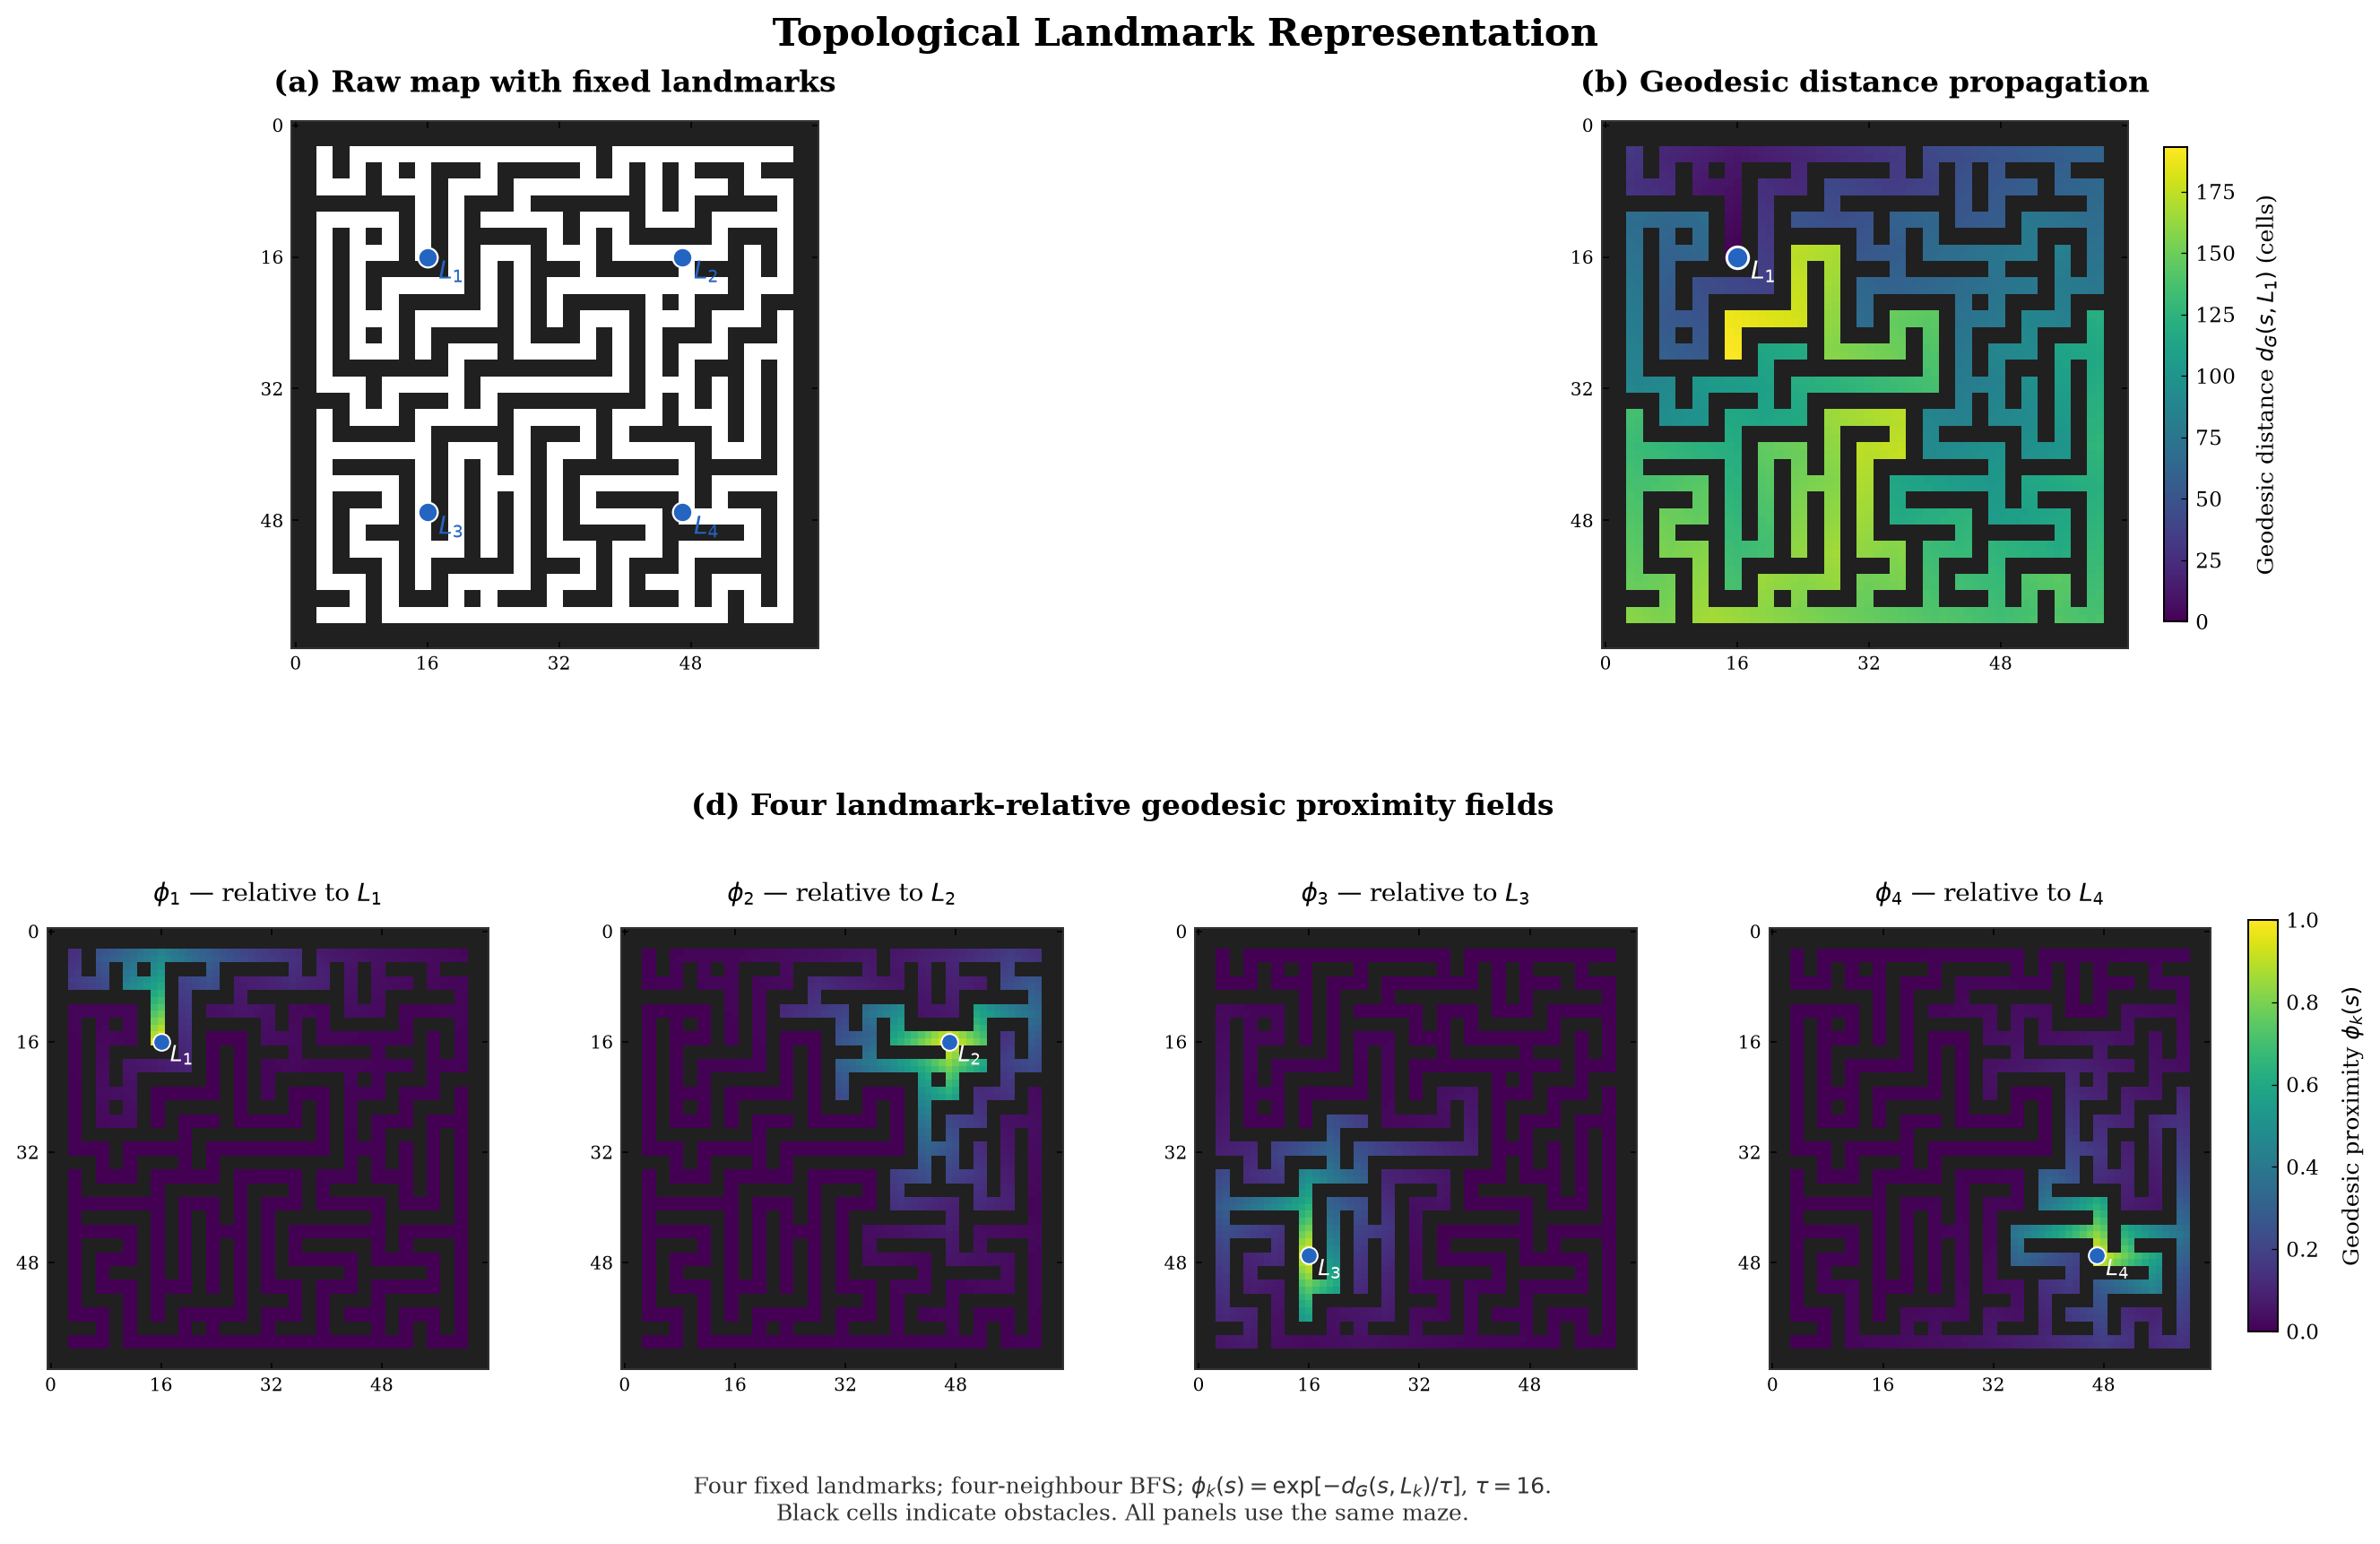

In [13]:
# ------------------------------------------------------------
# Load sample 0 from the ORIGINAL 3-channel dataset file
# ------------------------------------------------------------
if not SAMPLE_FILE.is_file():
    raise FileNotFoundError(
        f"Cannot find {SAMPLE_FILE.resolve()}. "
        "Set DATASET_DIR to the directory containing pair_00000.npz."
    )

with np.load(SAMPLE_FILE, allow_pickle=False) as npz:
    raw_map = np.asarray(npz["map"], dtype=np.float32)

assert raw_map.shape == (3, 64, 64), f"Unexpected map shape: {raw_map.shape}"

# Same functions, reference fractions and tau as the training notebook.
landmark_fields, distances, landmark_positions = encode_landmarks(raw_map[0])
condition_np = np.concatenate([raw_map, landmark_fields], axis=0)
assert condition_np.shape == (7, 64, 64)

print("Loaded:", SAMPLE_FILE.resolve())
print("Raw map:", raw_map.shape)
print("Landmark fields:", landmark_fields.shape)
print("Full conditioning shape:", condition_np.shape)
for k, pos in enumerate(landmark_positions, start=1):
    print(f"L{k}: (row={pos[0]}, col={pos[1]})")

# ------------------------------------------------------------
# Generate and save the same three figure panels
# ------------------------------------------------------------
plot_figure(raw_map, landmark_fields, distances, landmark_positions, OUTPUT_DIR, show=True)

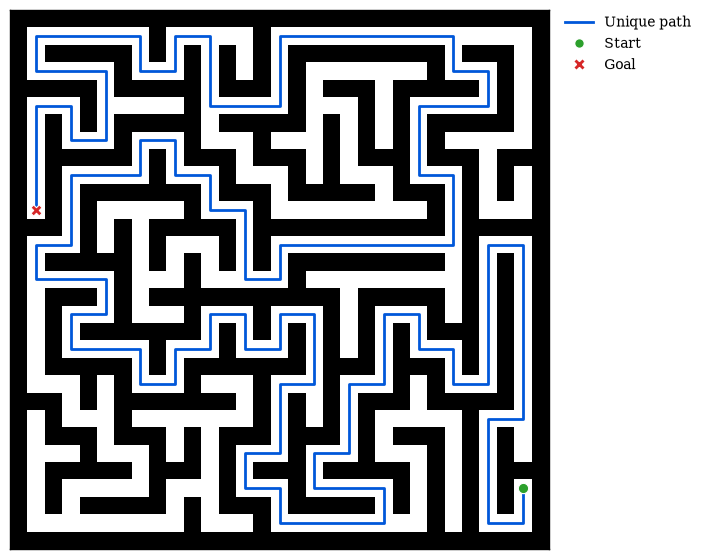

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
from matplotlib.lines import Line2D


# ============================================================
# Configuration
# ============================================================

LOGICAL_MAZE_SIZE = 15
SEED = 19

np.random.seed(SEED)


# ============================================================
# Plot style
# ============================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 1.2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "legend.frameon": False,
    "figure.dpi": 100,
})


# ============================================================
# 1. Generate a perfect maze using randomized DFS
# ============================================================

def generate_perfect_maze(logical_size=15):
    """
    Generate a perfect maze using randomized DFS.

    Returns
    -------
    maze : np.ndarray
        Binary maze of shape
        (2 * logical_size + 1, 2 * logical_size + 1)

        0 = free
        1 = wall
    """

    maze_size = 2 * logical_size + 1

    maze = np.ones(
        (maze_size, maze_size),
        dtype=np.uint8
    )

    visited = np.zeros(
        (logical_size, logical_size),
        dtype=bool
    )

    directions = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1),
    ]

    start_r = np.random.randint(logical_size)
    start_c = np.random.randint(logical_size)

    visited[start_r, start_c] = True
    maze[2 * start_r + 1, 2 * start_c + 1] = 0

    stack = [(start_r, start_c)]

    while stack:
        r, c = stack[-1]

        neighbors = []

        for dr, dc in directions:
            nr = r + dr
            nc = c + dc

            if (
                0 <= nr < logical_size
                and 0 <= nc < logical_size
                and not visited[nr, nc]
            ):
                neighbors.append((nr, nc, dr, dc))

        if not neighbors:
            stack.pop()
            continue

        nr, nc, dr, dc = neighbors[np.random.randint(len(neighbors))]

        current_r = 2 * r + 1
        current_c = 2 * c + 1

        wall_r = current_r + dr
        wall_c = current_c + dc

        maze[wall_r, wall_c] = 0
        maze[2 * nr + 1, 2 * nc + 1] = 0

        visited[nr, nc] = True
        stack.append((nr, nc))

    return maze


# ============================================================
# 2. BFS helper
# ============================================================

def bfs_farthest(maze, start):
    """
    Find the farthest reachable free cell from start.
    """

    H, W = maze.shape

    queue = deque([start])

    distances = {start: 0}
    parent = {start: None}

    directions = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1),
    ]

    farthest = start

    while queue:
        current = queue.popleft()
        r, c = current

        if distances[current] > distances[farthest]:
            farthest = current

        for dr, dc in directions:
            nr = r + dr
            nc = c + dc
            neighbor = (nr, nc)

            if nr < 0 or nr >= H or nc < 0 or nc >= W:
                continue

            if maze[nr, nc] == 1:
                continue

            if neighbor in distances:
                continue

            distances[neighbor] = distances[current] + 1
            parent[neighbor] = current
            queue.append(neighbor)

    return farthest, distances, parent


# ============================================================
# 3. Find a long unique path
# ============================================================

def find_long_path(maze):
    """
    Find a long path by two BFS passes.
    In a perfect maze, this path is unique.
    """

    free_cells = np.argwhere(maze == 0)
    initial = tuple(free_cells[0])

    endpoint_a, _, _ = bfs_farthest(maze, initial)
    endpoint_b, _, parent = bfs_farthest(maze, endpoint_a)

    path = []
    current = endpoint_b

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()

    return endpoint_a, endpoint_b, path


# ============================================================
# 4. Generate maze and path
# ============================================================

maze = generate_perfect_maze(LOGICAL_MAZE_SIZE)
start, goal, path = find_long_path(maze)
path = np.asarray(path)


# ============================================================
# 5. Plot
# ============================================================

fig, ax = plt.subplots(figsize=(7.8, 7.0))

# Maze background
ax.imshow(
    maze,
    cmap="binary",
    interpolation="nearest",
    origin="upper",
)

# Unique path
ax.plot(
    path[:, 1],
    path[:, 0],
    linewidth=2.0,
    color="#0057D9",
    zorder=3,
)

# Start
ax.scatter(
    start[1],
    start[0],
    s=55,
    marker="o",
    color="#2CA02C",
    edgecolor="white",
    linewidth=0.8,
    zorder=4,
)

# Goal
ax.scatter(
    goal[1],
    goal[0],
    s=65,
    marker="X",
    color="#D62728",
    edgecolor="white",
    linewidth=0.8,
    zorder=4,
)


# ============================================================
# Axes formatting
# ============================================================

H, W = maze.shape

ax.set_xlim(-0.5, W - 0.5)
ax.set_ylim(H - 0.5, -0.5)
ax.set_aspect("equal")

ax.set_xticks([])
ax.set_yticks([])

ax.set_xlabel("")
ax.set_ylabel("")

for spine in ax.spines.values():
    spine.set_linewidth(1.0)


# ============================================================
# Legend outside the figure
# ============================================================

legend_handles = [
    Line2D(
        [0], [0],
        color="#0057D9",
        linewidth=2.0,
        label="Unique path"
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor="#2CA02C",
        markeredgecolor="white",
        markersize=7,
        label="Start"
    ),
    Line2D(
        [0], [0],
        marker="X",
        linestyle="None",
        markerfacecolor="#D62728",
        markeredgecolor="white",
        markersize=8,
        label="Goal"
    ),
]

ax.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    borderaxespad=0.0,
    frameon=False
)


# ============================================================
# Layout
# ============================================================

plt.subplots_adjust(right=0.82)
plt.show()

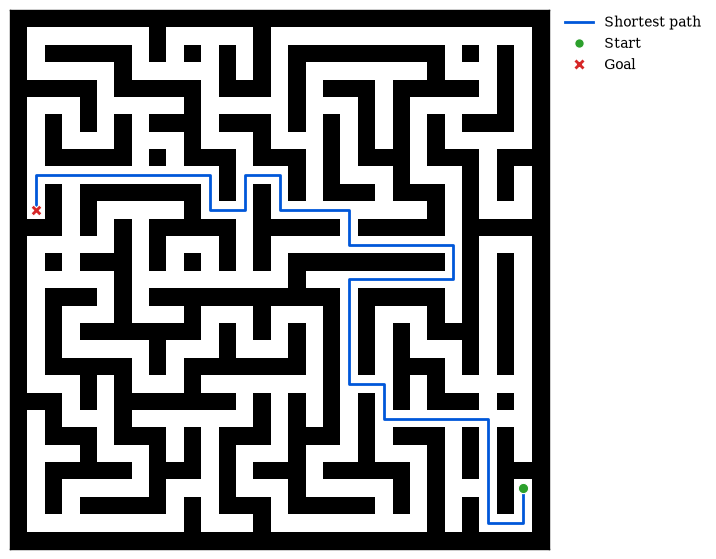

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
from matplotlib.lines import Line2D


# ============================================================
# Configuration
# ============================================================

LOGICAL_MAZE_SIZE = 15
SEED = 19

# proportion of eligible walls to remove
LOOP_PROB = 0.10

np.random.seed(SEED)


# ============================================================
# Plot style
# ============================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 1.2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "legend.frameon": False,
    "figure.dpi": 100,
})


# ============================================================
# 1. Generate a perfect maze using randomized DFS
# ============================================================

def generate_perfect_maze(logical_size=15):
    """
    Generate a perfect maze using randomized DFS.

    Returns
    -------
    maze : np.ndarray
        Binary maze of shape
        (2 * logical_size + 1, 2 * logical_size + 1)

        0 = free
        1 = wall
    """

    maze_size = 2 * logical_size + 1

    maze = np.ones(
        (maze_size, maze_size),
        dtype=np.uint8
    )

    visited = np.zeros(
        (logical_size, logical_size),
        dtype=bool
    )

    directions = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1),
    ]

    start_r = np.random.randint(logical_size)
    start_c = np.random.randint(logical_size)

    visited[start_r, start_c] = True
    maze[2 * start_r + 1, 2 * start_c + 1] = 0

    stack = [(start_r, start_c)]

    while stack:
        r, c = stack[-1]

        neighbors = []

        for dr, dc in directions:
            nr = r + dr
            nc = c + dc

            if (
                0 <= nr < logical_size
                and 0 <= nc < logical_size
                and not visited[nr, nc]
            ):
                neighbors.append((nr, nc, dr, dc))

        if not neighbors:
            stack.pop()
            continue

        nr, nc, dr, dc = neighbors[np.random.randint(len(neighbors))]

        current_r = 2 * r + 1
        current_c = 2 * c + 1

        wall_r = current_r + dr
        wall_c = current_c + dc

        maze[wall_r, wall_c] = 0
        maze[2 * nr + 1, 2 * nc + 1] = 0

        visited[nr, nc] = True
        stack.append((nr, nc))

    return maze


# ============================================================
# 2. Add loops by removing eligible walls
# ============================================================

def add_loops_to_maze(maze, loop_prob=0.10):
    """
    Convert a perfect maze into a maze-with-loops by removing
    a small proportion of eligible internal walls.

    An eligible wall is:
        - an internal wall cell
        - separating two existing free passages
        - either horizontally or vertically

    Parameters
    ----------
    maze : np.ndarray
        Perfect maze, 0 = free, 1 = wall
    loop_prob : float
        Probability of removing each eligible wall

    Returns
    -------
    maze_looped : np.ndarray
        Maze with loops
    """

    maze_looped = maze.copy()
    H, W = maze_looped.shape

    candidate_walls = []

    for r in range(1, H - 1):
        for c in range(1, W - 1):

            # only consider wall cells
            if maze_looped[r, c] != 1:
                continue

            # case 1:
            # free | wall | free
            if (
                r % 2 == 1 and c % 2 == 0
                and maze_looped[r, c - 1] == 0
                and maze_looped[r, c + 1] == 0
            ):
                candidate_walls.append((r, c))

            # case 2:
            # free
            # wall
            # free
            elif (
                r % 2 == 0 and c % 2 == 1
                and maze_looped[r - 1, c] == 0
                and maze_looped[r + 1, c] == 0
            ):
                candidate_walls.append((r, c))

    for r, c in candidate_walls:
        if np.random.rand() < loop_prob:
            maze_looped[r, c] = 0

    return maze_looped


# ============================================================
# 3. BFS helpers
# ============================================================

def bfs_farthest(maze, start):
    """
    Find the farthest reachable free cell from start.
    """

    H, W = maze.shape

    queue = deque([start])

    distances = {start: 0}
    parent = {start: None}

    directions = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1),
    ]

    farthest = start

    while queue:
        current = queue.popleft()
        r, c = current

        if distances[current] > distances[farthest]:
            farthest = current

        for dr, dc in directions:
            nr = r + dr
            nc = c + dc
            neighbor = (nr, nc)

            if nr < 0 or nr >= H or nc < 0 or nc >= W:
                continue

            if maze[nr, nc] == 1:
                continue

            if neighbor in distances:
                continue

            distances[neighbor] = distances[current] + 1
            parent[neighbor] = current
            queue.append(neighbor)

    return farthest, distances, parent


def bfs_shortest_path(maze, start, goal):
    """
    Compute one shortest path between start and goal
    in an unweighted maze.
    """

    H, W = maze.shape

    queue = deque([start])
    parent = {start: None}

    directions = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1),
    ]

    while queue:
        current = queue.popleft()

        if current == goal:
            break

        r, c = current

        for dr, dc in directions:
            nr = r + dr
            nc = c + dc
            neighbor = (nr, nc)

            if nr < 0 or nr >= H or nc < 0 or nc >= W:
                continue

            if maze[nr, nc] == 1:
                continue

            if neighbor in parent:
                continue

            parent[neighbor] = current
            queue.append(neighbor)

    if goal not in parent:
        return None

    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()
    return path


# ============================================================
# 4. Find a long path in the perfect maze
# ============================================================

def find_long_path(maze):
    """
    Find a long path by two BFS passes.
    In a perfect maze, this path is unique.
    """

    free_cells = np.argwhere(maze == 0)
    initial = tuple(free_cells[0])

    endpoint_a, _, _ = bfs_farthest(maze, initial)
    endpoint_b, _, parent = bfs_farthest(maze, endpoint_a)

    path = []
    current = endpoint_b

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()

    return endpoint_a, endpoint_b, path


# ============================================================
# 5. Generate perfect maze and looped maze
# ============================================================

perfect_maze = generate_perfect_maze(LOGICAL_MAZE_SIZE)

# same start / goal as the perfect-maze figure
start, goal, perfect_path = find_long_path(perfect_maze)

# create looped version from the SAME perfect maze
looped_maze = add_loops_to_maze(perfect_maze, loop_prob=LOOP_PROB)

# compute one shortest path in the looped maze
looped_path = bfs_shortest_path(looped_maze, start, goal)
looped_path = np.asarray(looped_path)


# ============================================================
# 6. Plot looped maze
# ============================================================

fig, ax = plt.subplots(figsize=(7.8, 7.0))

# Maze background
ax.imshow(
    looped_maze,
    cmap="binary",
    interpolation="nearest",
    origin="upper",
)

# Shortest path
ax.plot(
    looped_path[:, 1],
    looped_path[:, 0],
    linewidth=2.0,
    color="#0057D9",
    zorder=3,
)

# Start
ax.scatter(
    start[1],
    start[0],
    s=55,
    marker="o",
    color="#2CA02C",
    edgecolor="white",
    linewidth=0.8,
    zorder=4,
)

# Goal
ax.scatter(
    goal[1],
    goal[0],
    s=65,
    marker="X",
    color="#D62728",
    edgecolor="white",
    linewidth=0.8,
    zorder=4,
)


# ============================================================
# Axes formatting
# ============================================================

H, W = looped_maze.shape

ax.set_xlim(-0.5, W - 0.5)
ax.set_ylim(H - 0.5, -0.5)
ax.set_aspect("equal")

ax.set_xticks([])
ax.set_yticks([])

ax.set_xlabel("")
ax.set_ylabel("")

for spine in ax.spines.values():
    spine.set_linewidth(1.0)


# ============================================================
# Legend outside the figure
# ============================================================

legend_handles = [
    Line2D(
        [0], [0],
        color="#0057D9",
        linewidth=2.0,
        label="Shortest path"
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor="#2CA02C",
        markeredgecolor="white",
        markersize=7,
        label="Start"
    ),
    Line2D(
        [0], [0],
        marker="X",
        linestyle="None",
        markerfacecolor="#D62728",
        markeredgecolor="white",
        markersize=8,
        label="Goal"
    ),
]

ax.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    borderaxespad=0.0,
    frameon=False
)


# ============================================================
# Layout
# ============================================================

plt.subplots_adjust(right=0.82)
plt.show()